# ArchR pipeline

This notebook contains QC, processing and plotting of snATACseq data. Input files are two arrow files that were created using the create_arrow_files_archR.ipynb notebook.

# Basic processing

Imports arrow files, creates a project, performs basic QC, calls peaks & does some preliminary clustering.

In [1]:
version

               _                           
platform       aarch64-apple-darwin20      
arch           aarch64                     
os             darwin20                    
system         aarch64, darwin20           
status                                     
major          4                           
minor          5.0                         
year           2025                        
month          04                          
day            11                          
svn rev        88135                       
language       R                           
version.string R version 4.5.0 (2025-04-11)
nickname       How About a Twenty-Six      

In [2]:
renv::init()
renv::activate()
renv::status()

- Using Bioconductor version '3.21'.
- The project is out-of-sync -- use `renv::status()` for details.
The following package(s) are in an inconsistent state:

 package              installed recorded used
 ArchR                y         n        y   
 base64enc            y         n        y   
 Biobase              y         n        y   
 BiocGenerics         y         n        y   
 BiocIO               y         n        y   
 BiocParallel         y         n        y   
 BiocVersion          y         n        y   
 Biostrings           y         n        y   
 bit                  y         n        y   
 bit64                y         n        y   
 blob                 y         n        y   
 brew                 y         n        y   
 brio                 y         n        y   
 BSgenome             y         n        y   
 callr                y         n        y   
 chromVAR             y         n        y   
 chromVARmotifs       y         n        y   
 circlize    

In [3]:
library(ArchR)
library(ggrepel)
library(pheatmap)
library(patchwork)
library(svglite)
library(gridExtra)
library(viridis)


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

Set genome to mm10.

In [4]:
addArchRGenome("mm10")
addArchRThreads(threads = 16)

Setting default genome to Mm10.

Input threads is equal to or greater than ncores minus 1 (7)
Setting cores to ncores minus 2. Set force = TRUE to set above this number!

Setting default number of Parallel threads to 6.



Import Arrow files (created using create_arrow_files_archR.ipynb)

In [5]:
ArrowFiles <- c("HFD.arrow", "LFD.arrow")

# Create project file
proj <- ArchRProject(
  ArrowFiles = ArrowFiles,
  outputDirectory = "ArchR",
  copyArrows = FALSE
)

Using GeneAnnotation set by addArchRGenome(Mm10)!

Using GeneAnnotation set by addArchRGenome(Mm10)!

Validating Arrows...

Getting SampleNames...



Getting Cell Metadata...



Merging Cell Metadata...

Initializing ArchRProject...


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,-

# QC

Plot TSS, fragment size distribution and fragments per cell

1 


Picking joint bandwidth of 0.0624

ArchR logging to : ArchRLogs/ArchR-plotFragmentSizes-106c0744ebb12-Date-2025-07-29_Time-09-05-37.409778.log
If there is an issue, please report to github with logFile!

ArchR logging successful to : ArchRLogs/ArchR-plotFragmentSizes-106c0744ebb12-Date-2025-07-29_Time-09-05-37.409778.log



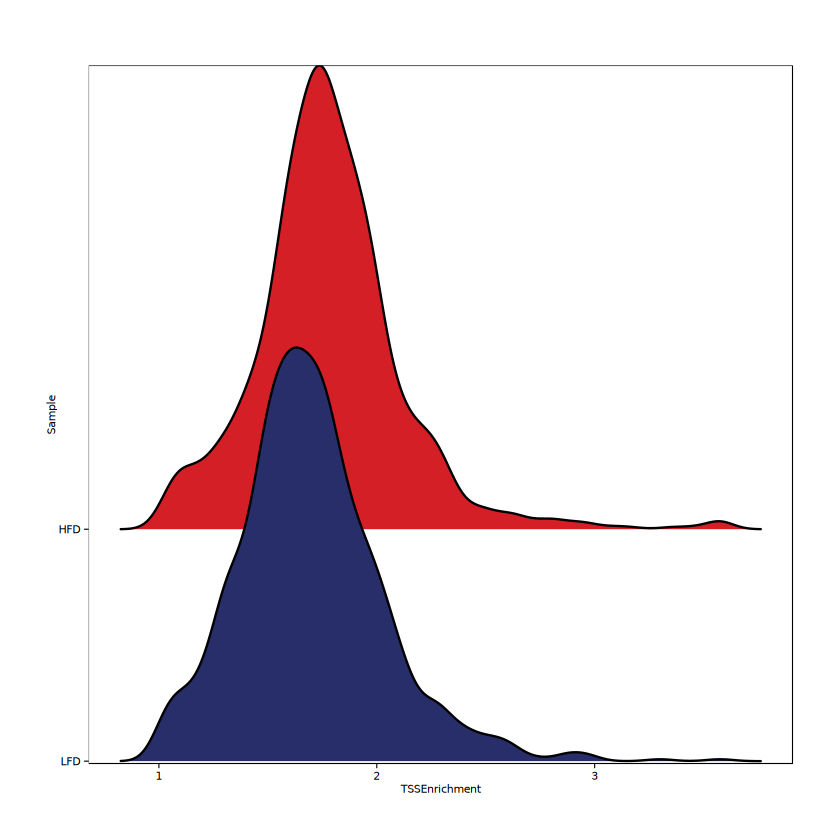

1 


Picking joint bandwidth of 2620



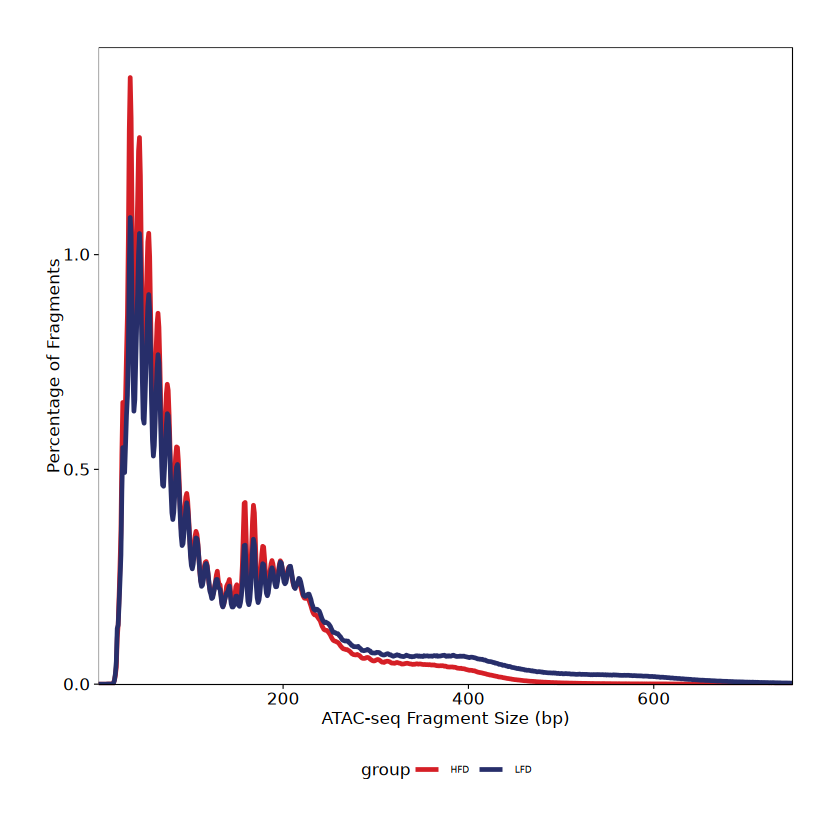

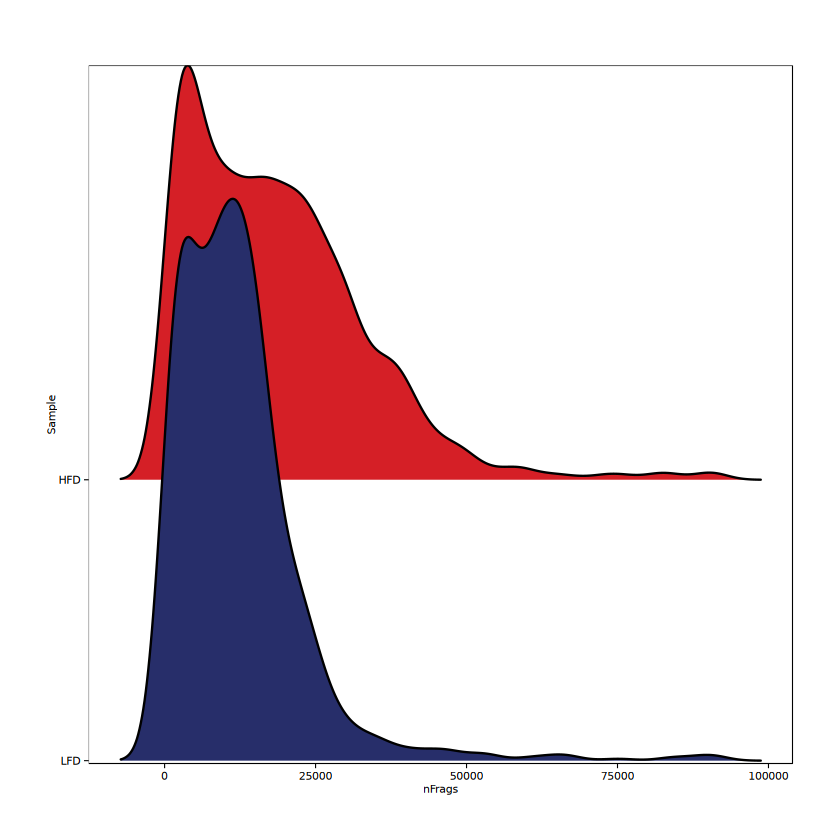

In [6]:
# TSS enrichment
p1 <- plotGroups(ArchRProj = proj, groupBy = "Sample", colorBy = "cellColData", name = "TSSEnrichment")
p1

# Fragment size distribution
p2 <- plotFragmentSizes(ArchRProj = proj)
p2

# Number of fragments per cell
p3 <- plotGroups(ArchRProj = proj, groupBy = "Sample", colorBy = "cellColData", name = "nFrags")
p3

# Peak Calling

Inbuilt ArchR function for peak calling.

In [7]:
proj <- addGroupCoverages(
  ArchRProj = proj,
  groupBy = "Sample", 
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addGroupCoverages-106c05cb2ed78-Date-2025-07-29_Time-09-06-01.192063.log
If there is an issue, please report to github with logFile!

Skipping validation of empty chromosomes since `force` = TRUE!

HFD (1 of 2) : CellGroups N = 2

LFD (2 of 2) : CellGroups N = 2

2025-07-29 09:06:01.420253 : Creating Coverage Files!, 0.004 mins elapsed.

2025-07-29 09:06:01.421899 : Batch Execution w/ safelapply!, 0.004 mins elapsed.

2025-07-29 09:06:01.426804 : Group HFD._.Rep1 (1 of 4) : Creating Group Coverage File : HFD._.Rep1.insertions.coverage.h5, 0.004 mins elapsed.

Number of Cells = 500

Coverage File Exists!

Added Coverage Group

Added Metadata Group

Added ArrowCoverage Class

Added Coverage/Info

Added Coverage/Info/CellNames

2025-07-29 09:06:18.198274 : Group HFD._.Rep2 (2 of 4) : Creating Group Coverage File : HFD._.Rep2.insertions.coverage.h5, 0.283 mins elapsed.

Number of Cells = 40

Coverage File Exists!

Added Coverage Group

Added Metadata Grou

Use MACS2 to for peak calling - need to adjust the path according to where MACS2 has been installed.

In [8]:
proj <- addReproduciblePeakSet(
  ArchRProj = proj,
  groupBy = "Sample",
  maxCells = 800,
  pathToMacs2 = "/Users/scc/miniconda3/envs/snatacseq_new/bin/macs2",
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addReproduciblePeakSet-106c0520b21cf-Date-2025-07-29_Time-09-07-15.047403.log
If there is an issue, please report to github with logFile!

Calling Peaks with Macs2

2025-07-29 09:07:15.117378 : Peak Calling Parameters!, 0.001 mins elapsed.



    Group nCells nCellsUsed nReplicates nMin nMax maxPeaks
HFD   HFD   3038        540           2   40  500   150000
LFD   LFD   2713        540           2   40  500   150000


2025-07-29 09:07:15.121445 : Batching Peak Calls!, 0.001 mins elapsed.

2025-07-29 09:07:15.125861 : Batch Execution w/ safelapply!, 0 mins elapsed.

2025-07-29 09:07:55.962799 : Identifying Reproducible Peaks!, 0.682 mins elapsed.

2025-07-29 09:07:58.376882 : Creating Union Peak Set!, 0.722 mins elapsed.

Converged after 3 iterations!

Plotting Ggplot!

2025-07-29 09:08:00.023575 : Finished Creating Union Peak Set (53570)!, 0.75 mins elapsed.



In [9]:
proj <- addPeakMatrix(proj)

ArchR logging to : ArchRLogs/ArchR-addPeakMatrix-106c06e6556d1-Date-2025-07-29_Time-09-08-00.050927.log
If there is an issue, please report to github with logFile!

2025-07-29 09:08:00.161032 : Batch Execution w/ safelapply!, 0 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-addPeakMatrix-106c06e6556d1-Date-2025-07-29_Time-09-08-00.050927.log



# Clustering

Initial clustering with default parameters.

In [10]:
proj <- addIterativeLSI(
  ArchRProj = proj,
  useMatrix = "TileMatrix",
  name = "IterativeLSI",
  iterations = 2,
  force = TRUE
)

Checking Inputs...

ArchR logging to : ArchRLogs/ArchR-addIterativeLSI-106c06d0c6e3b-Date-2025-07-29_Time-09-08-51.507079.log
If there is an issue, please report to github with logFile!

2025-07-29 09:08:51.632111 : Computing Total Across All Features, 0.001 mins elapsed.

2025-07-29 09:08:52.862192 : Computing Top Features, 0.022 mins elapsed.

###########
2025-07-29 09:08:53.419178 : Running LSI (1 of 2) on Top Features, 0.031 mins elapsed.
###########

2025-07-29 09:08:53.426165 : Creating Partial Matrix, 0.031 mins elapsed.

2025-07-29 09:09:03.46995 : Computing LSI, 0.198 mins elapsed.

2025-07-29 09:09:12.093381 : Identifying Clusters, 0.342 mins elapsed.

2025-07-29 09:09:17.805237 : Identified 6 Clusters, 0.437 mins elapsed.

2025-07-29 09:09:17.812823 : Saving LSI Iteration, 0.437 mins elapsed.

2025-07-29 09:09:25.58807 : Creating Cluster Matrix on the total Group Features, 0.567 mins elapsed.

2025-07-29 09:09:42.24195 : Computing Variable Features, 0.845 mins elapsed.

####

Calculate & add clusters

In [11]:
proj <- addClusters(
  input = proj,
  method = "Seurat",
  name = "Clusters", 
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addClusters-106c068d6eb2d-Date-2025-07-29_Time-09-09-59.030353.log
If there is an issue, please report to github with logFile!

2025-07-29 09:09:59.134665 : Running Seurats FindClusters (Stuart et al. Cell 2019), 0.001 mins elapsed.

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5751
Number of edges: 206125

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8427
Number of communities: 12
Elapsed time: 0 seconds


2025-07-29 09:10:03.389184 : Testing Outlier Clusters, 0.072 mins elapsed.

2025-07-29 09:10:03.391705 : Assigning Cluster Names to 12 Clusters, 0.072 mins elapsed.

2025-07-29 09:10:03.427097 : Finished addClusters, 0.072 mins elapsed.



Calculate & add UMAP

09:10:03 UMAP embedding parameters a = 0.7669 b = 1.223

09:10:03 Read 5751 rows and found 30 numeric columns

09:10:03 Using Annoy for neighbor search, n_neighbors = 40

09:10:03 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

09:10:03 Writing NN index file to temp file /var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T//RtmpEAaRzZ/file106c01092365e

09:10:03 Searching Annoy index using 4 threads, search_k = 4000

09:10:04 Annoy recall = 100%

09:10:04 Commencing smooth kNN distance calibration using 4 threads
 with target n_neighbors = 40

09:10:05 Initializing from normalized Laplacian + noise (using RSpectra)

09:10:05 Commencing optimization for 500 epochs, with 324584 positive edges

09:10:05 Using rng type: pcg

09:10:09 Optimization finished

09:10:09 Creating te

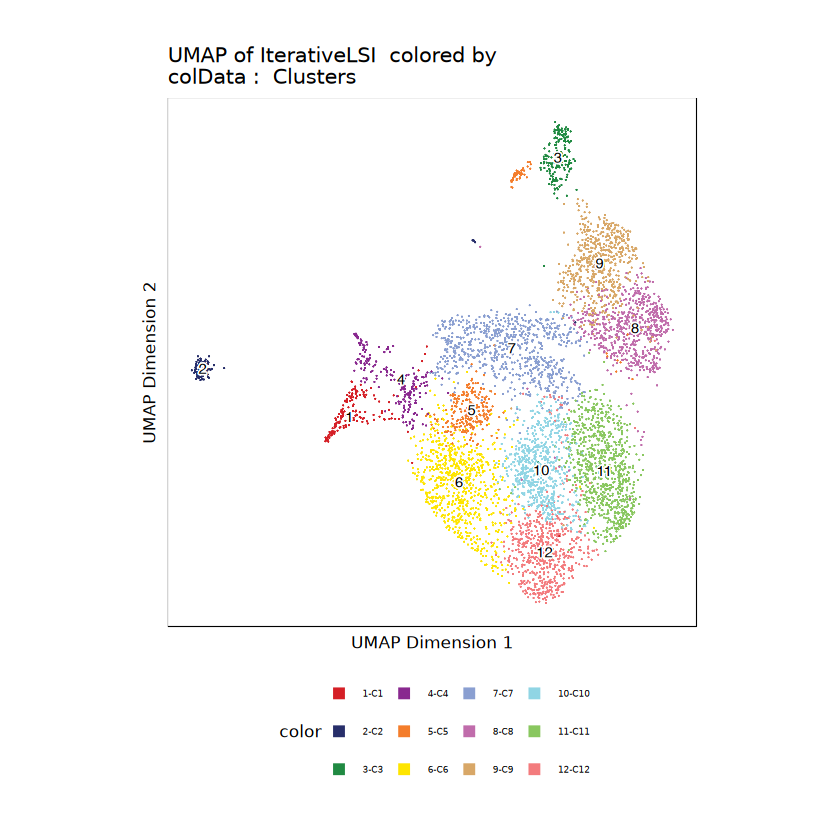

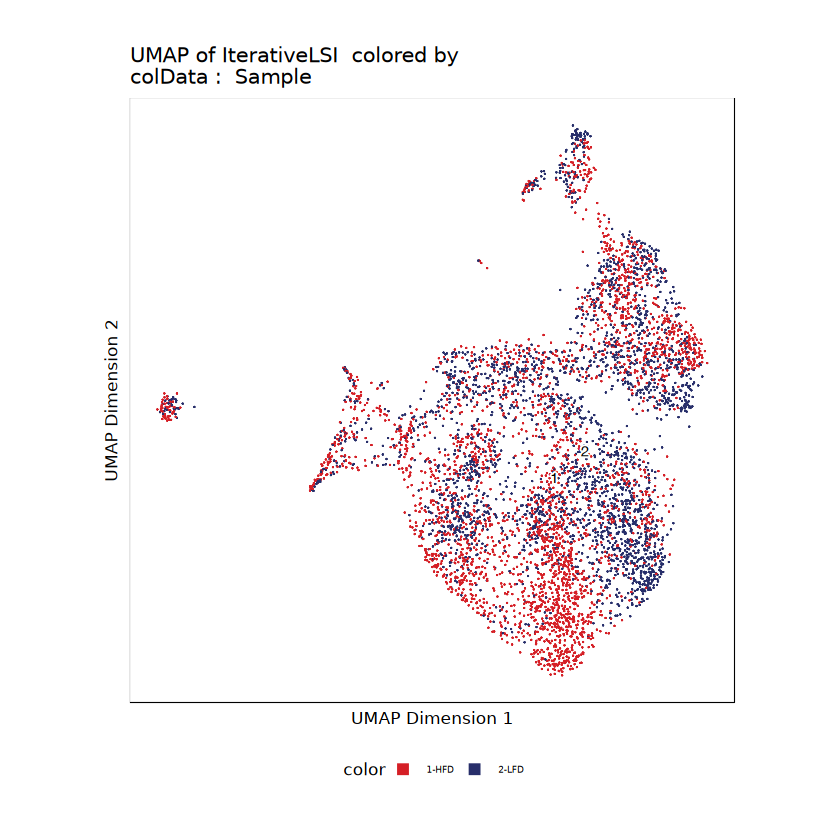

In [12]:
proj <- addUMAP(
  ArchRProj = proj,
)
plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Clusters")
plotEmbedding(proj, colorBy = "cellColData", name = "Sample")  

# Calculate top markers per cluster

Calculate top markers for each cluster (gene-level scores - imputed gene expression from chromatin accessibility)

In [13]:
markers <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Clusters",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c068bb34d2-Date-2025-07-29_Time-09-10-12.128653.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2025-07-29 09:10:12.331291 : Matching Known Biases, 0.002 mins elapsed.

###########
2025-07-29 09:12:24.343813 : Completed Pairwise Tests, 2.202 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-106c068bb34d2-Date-2025-07-29_Time-09-10-12.128653.log



In [14]:
genes_all_clusters <- getMarkers(markers, cutOff = "FDR <= 1")

Save all significant (FDR < 0.05) markers as csv

In [15]:
for(i in 1:12) {
    cluster_data <- genes_all_clusters[[i]]
    
    # Filter for significant genes
    genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05, ]
    
    # Optional: Add fold change filtering
    # genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & abs(cluster_data$Log2FC) > 1, ]
    
    # Save 
    filename <- paste0("significant_genes_per_cluster/cluster_", i, "_significant_genes.csv")
    write.csv(genes_clusters_sig, filename, row.names = FALSE)
    
    print(paste("Cluster", i, ":", nrow(genes_clusters_sig), "significant genes saved to", filename))
}

[1] "Cluster 1 : 11203 significant genes saved to significant_genes_per_cluster/cluster_1_significant_genes.csv"
[1] "Cluster 2 : 3578 significant genes saved to significant_genes_per_cluster/cluster_2_significant_genes.csv"
[1] "Cluster 3 : 3835 significant genes saved to significant_genes_per_cluster/cluster_3_significant_genes.csv"
[1] "Cluster 4 : 8573 significant genes saved to significant_genes_per_cluster/cluster_4_significant_genes.csv"
[1] "Cluster 5 : 582 significant genes saved to significant_genes_per_cluster/cluster_5_significant_genes.csv"
[1] "Cluster 6 : 4276 significant genes saved to significant_genes_per_cluster/cluster_6_significant_genes.csv"
[1] "Cluster 7 : 3587 significant genes saved to significant_genes_per_cluster/cluster_7_significant_genes.csv"
[1] "Cluster 8 : 5098 significant genes saved to significant_genes_per_cluster/cluster_8_significant_genes.csv"
[1] "Cluster 9 : 5567 significant genes saved to significant_genes_per_cluster/cluster_9_significant_gen

Top markers HFD vs LFD

In [16]:
markers_condition <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Sample",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c02e485fda-Date-2025-07-29_Time-09-12-26.635992.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2025-07-29 09:12:26.788065 : Matching Known Biases, 0.001 mins elapsed.

###########
2025-07-29 09:12:40.845463 : Completed Pairwise Tests, 0.236 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-106c02e485fda-Date-2025-07-29_Time-09-12-26.635992.log



In [17]:
top_genes_per_sample <- getMarkers(markers_condition, cutOff = "FDR <= 1")

In [18]:
top_genes_per_sample

List of length 2
names(2): HFD LFD

In [19]:
for(i in 1:2) {
    cluster_data <- top_genes_per_sample[[i]]
    
    # Filter for significant genes
    genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & cluster_data$Log2FC > 1, ]
    
    # Optional: Add fold change filtering
    # genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & abs(cluster_data$Log2FC) > 1, ]
    
    # Save
    if(i == 1) {
        filename <- "significant_genes_per_condition/significant_genes_hfd.csv"
    } else {
        filename <- "significant_genes_per_condition/significant_genes_lfd.csv"
    }
    write.csv(genes_clusters_sig, filename, row.names = FALSE)
    
    print(paste(i, ":", nrow(genes_clusters_sig), "significant genes saved to", filename))
}

[1] "1 : 30 significant genes saved to significant_genes_per_condition/significant_genes_hfd.csv"
[1] "2 : 13 significant genes saved to significant_genes_per_condition/significant_genes_lfd.csv"


# Cluster identification

Define markers of interest that help us define the clusters. Two lists (markerGenes and additionalGenes) that can be modified as needed.

In [20]:
markerGenes <- c("Cd69",
"Gata3",
"Foxp3",
"Tbx21",
"Rorc",
"Nr1d1",
"Il2",
"Stat3",
# "Stat5",
"Irf4",
"Cd44",
"Sell",
"Il17a",
"Il17f",
"Il22",
"Il21",
"Il23r",
"Il1r1",
"Ikzf2",
"Icos",
"Il1r2",
"Tox",
"Pparg",
"Rora",
"Il19",
"Il1rl1",
"Il7r",
"Il2ra",
"Ifng",
"Cat",
"S1pr1",
"Bcl2",
"Klf2",
"Ccr7",
"Il5",
"Il13")

In [21]:
additionalGenes <- c("Itgae", "Itga1", "Runx3", "Prdm1", "Cxcr6", "Ifng", "Tnf", "Il2ra", "Il10", "Bcl2", "Bcl2a1a", "Il7r", "Nr4a1", "Fabp4", "Fabp5", "Ccr8", "Ccr10", "S1pr1", "Sell", "Tcf7", "Lef1", "Eomes", "Tbx21", "Rorc", "Gzmb", "Prf1", "Cd69", "Batf", "Ccr6")

Calculate gene score for each gene in the markerGenes list. 

In [22]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c022f955e3-Date-2025-07-29_Time-09-12-41.438374.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 09:12:41.597355 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c022f955e3-Date-2025-07-29_Time-09-12-41.438374.log



Plot the gene score on UMAP

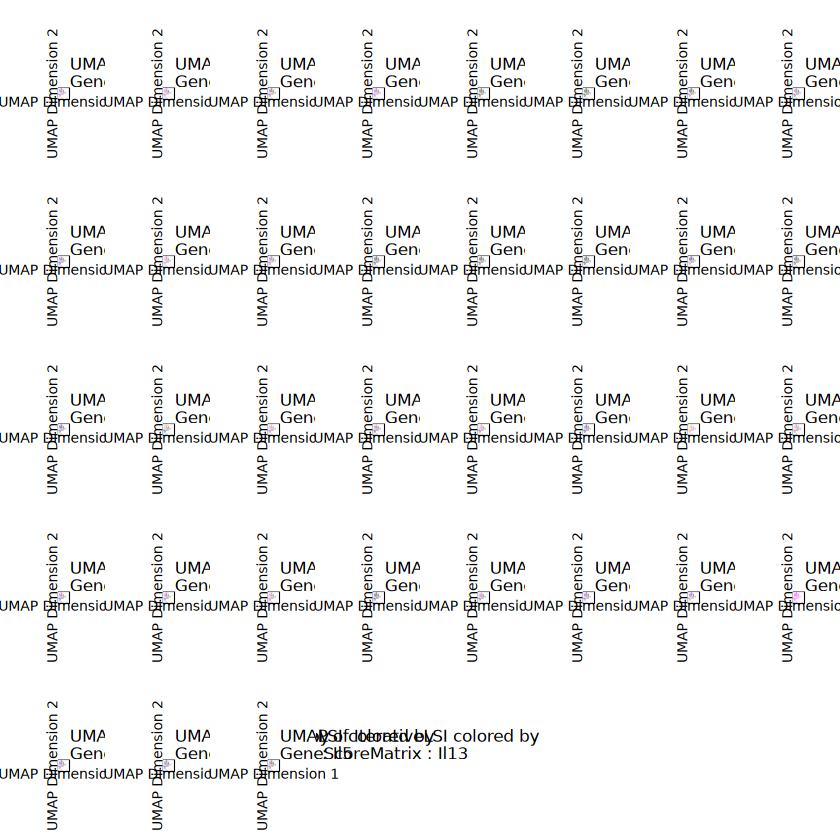

In [44]:
p2 <- lapply(p, function(x){
    x + guides(color = FALSE, fill = FALSE) + 
    theme_ArchR(baseSize = 8) +
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank()
    ) 
})

combined_plot <- do.call(gridExtra::grid.arrange, c(p2, ncol = 8))

# Save
ggsave("plots/combined_plot_RAW.pdf", combined_plot, width = 30, height = 20, units = "in", dpi = 300)

Gene score plots are quite variable - this is just because of the sparsity of the snATACseq data (most genes have no accessibility signal in most cells). We use MAGIC to impute gene scores (inbuilt in ArchR; it smoothes the signal across nearby cells).

In [45]:
proj <- addImputeWeights(proj)


ArchR logging to : ArchRLogs/ArchR-addImputeWeights-106c037f805ad-Date-2025-07-29_Time-09-35-59.671451.log
If there is an issue, please report to github with logFile!

2025-07-29 09:35:59.828349 : Computing Impute Weights Using Magic (Cell 2018), 0 mins elapsed.



Get imputed gene scores for all genes and plot markerGenes on UMAP

In [46]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    imputeWeights = getImputeWeights(proj),
    force = TRUE
)

Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c02e026013-Date-2025-07-29_Time-09-36-03.153794.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 09:36:03.358407 : 



Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c02e026013-Date-2025-07-29_Time-09-36-03.153794.log



Plot the new imputed weights with a fixed scale (to make the gene score levels comparable)

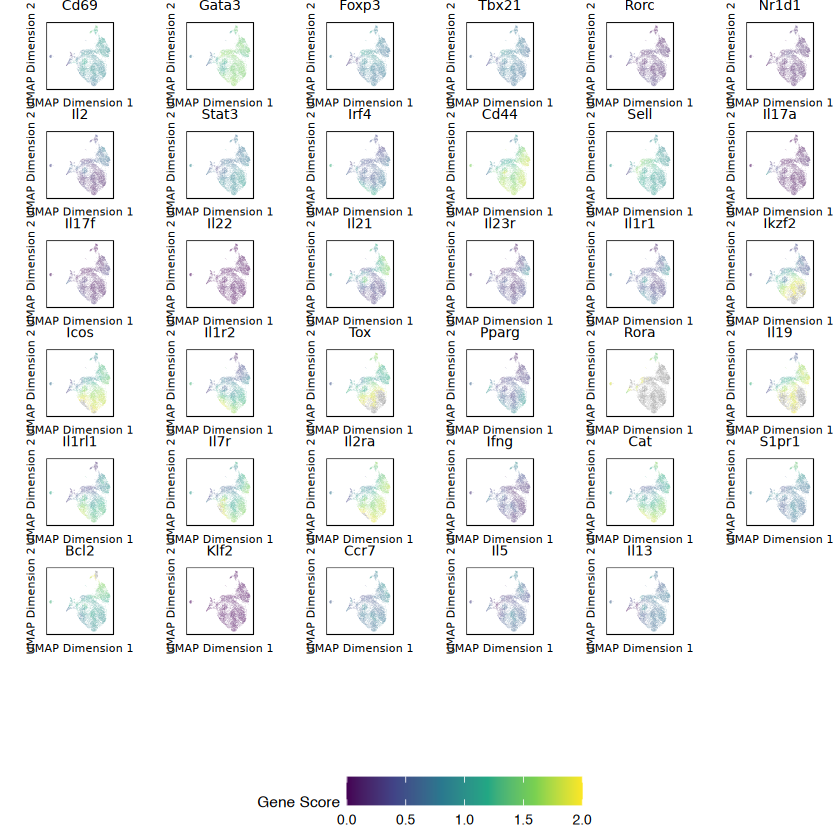

In [ ]:
# Apply fixed scale from 0 to 2 to all plots
p2 <- lapply(p, function(x){
    # Remove any existing scales 
    x$scales$scales <- list()
    
    x + 
    scale_color_viridis_c(
        limits = c(0, 2),  # Changed to 0-2 
        name = "Gene Score"
    ) +
    scale_fill_viridis_c(
        limits = c(0, 2),  # Changed to 0-2 
    ) +
    guides(color = FALSE, fill = FALSE) +  # Remove all legends
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0, 0, 0, 0), "cm")) +
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5)
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    # Extract gene name
    gene_name <- names(p)[i] 
    
    p2[[i]] + ggtitle(gene_name)
})

# Create a dummy plot with the gene score scale to extract the legend
dummy_data <- data.frame(x = 1:100, y = 1:100, value = seq(0, 2, length.out = 100))
legend_plot <- ggplot(dummy_data, aes(x = x, y = y, color = value)) +
    geom_point() +
    scale_color_viridis_c(  # Changed to viridis
        limits = c(0, 2),
        name = "Gene Score"
    ) +
    theme_void() +
    theme(legend.position = "bottom",
          legend.key.width = unit(1, "cm"),
          legend.text = element_text(size = 8),
          legend.title = element_text(size = 9))

# Extract the legend
legend <- cowplot::get_legend(legend_plot)

# Create the main plot grid 
main_plot <- do.call(cowplot::plot_grid, c(list(ncol = 6), p2[1:40]))

# Combine main plot with legend below
cowplot::plot_grid(main_plot, legend, 
                   ncol = 1, 
                   rel_heights = c(1, 0.1))

Same plots but with individual scales for each gene

In [48]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c05630389c-Date-2025-07-29_Time-09-36-15.691049.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 09:36:15.867664 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c05630389c-Date-2025-07-29_Time-09-36-15.691049.log



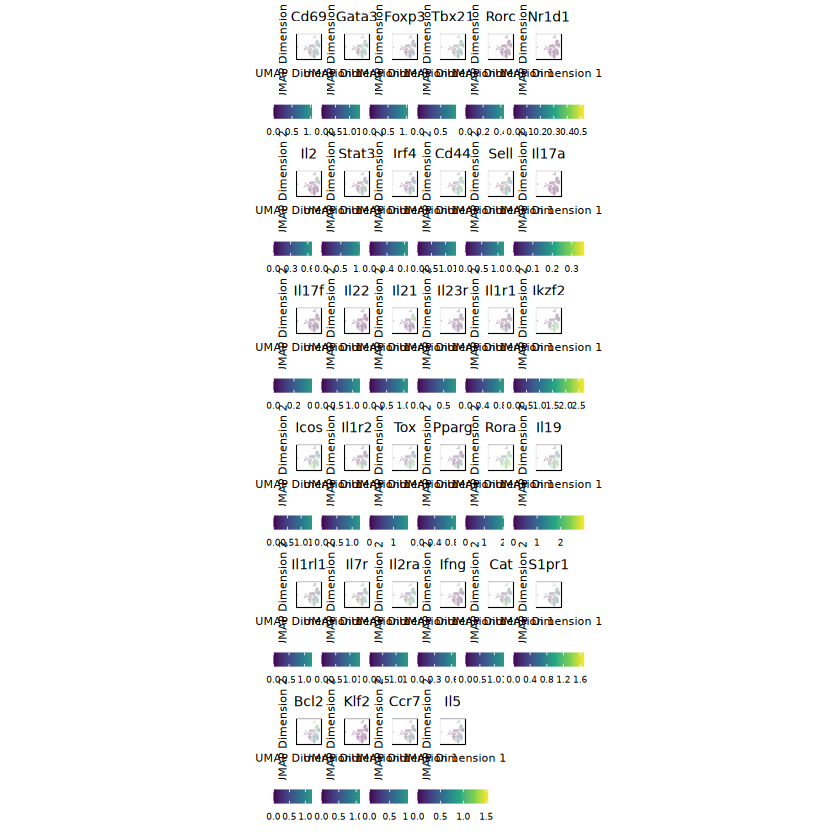

In [ ]:
p2 <- lapply(p, function(x){
    x$scales$scales <- list()
    
    x + 
    scale_color_viridis_c(
        name = ""  
    ) +
    scale_fill_viridis_c(
        name = "" 
    ) +
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm")) +  
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5),
        legend.key.size = unit(0.3, "cm"), 
        legend.text = element_text(size = 5),  
        legend.title = element_blank(),  
        legend.position = "bottom"  # Legend at bottom
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    gene_name <- names(p)[i] 
    p2[[i]] + ggtitle(gene_name)
})

# Create the grid using patchwork with individual legends
combined_plot <- wrap_plots(p2[1:34], ncol = 6)

# Display
print(combined_plot)

# Save with even larger dimensions for bigger plots
ggsave("plots/gene_plots_individual_scales.pdf", combined_plot, 
       width = 15, height = 20, 
       units = "in", dpi = 300)

Same with list of additional genes.

In [50]:
p_additionalgenes <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = additionalGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c03f304c58-Date-2025-07-29_Time-09-36-31.212389.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 09:36:31.366218 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c03f304c58-Date-2025-07-29_Time-09-36-31.212389.log



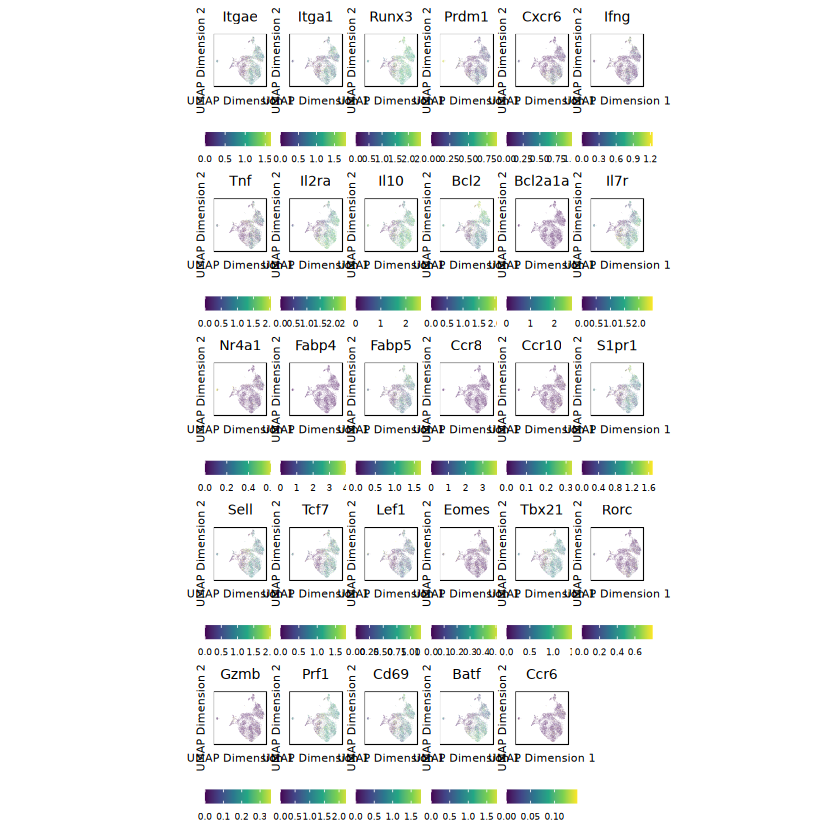

In [ ]:
p2 <- lapply(p_additionalgenes, function(x){
    x$scales$scales <- list()
    
    x + 
    scale_color_viridis_c(
        name = "" 
    ) +
    scale_fill_viridis_c(
        name = "" 
    ) +
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm")) +  
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5),
        legend.key.size = unit(0.3, "cm"), 
        legend.text = element_text(size = 5),  
        legend.title = element_blank(),  
        legend.position = "bottom"  # Legend at bottom
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    gene_name <- names(p_additionalgenes)[i] 
    p2[[i]] + ggtitle(gene_name)
})

# Create the grid using patchwork with individual legends
combined_plot <- wrap_plots(p2[1:29], ncol = 6)

# Display
print(combined_plot)

# Save 
ggsave("plots/gene_plots_individual_scales_additionalgenes.pdf", combined_plot, 
       width = 15, height = 20, 
       units = "in", dpi = 300)

## Calculate top 10 markers per cluster

In [52]:
marker_data <- assays(markers)$Log2FC
marker_fdr <- assays(markers)$FDR
gene_names <- rowData(markers)$name

# Find significant markers for each cluster
significant_markers <- which(marker_fdr <= 0.01 & marker_data >= 1.0)

# Get top markers for each cluster
top_markers_per_cluster <- list()
for(i in 1:ncol(markers)) {
    cluster_markers <- which(marker_fdr[,i] <= 0.01 & marker_data[,i] >= 1.0)
    top_cluster <- cluster_markers[order(marker_data[cluster_markers,i], decreasing = TRUE)]
    top_markers_per_cluster[[i]] <- gene_names[top_cluster[1:10]]  # Top 10 per cluster
}

In [53]:
top_markers_per_cluster

[[1]]
 [1] "Olfr480"       "Mir5107"       "Ccdc89"        "Rpl8"         
 [5] "Olfr1392"      "Mansc4"        "Olfr1417"      "Cypt12"       
 [9] "A230056P14Rik" "Olfr1294"     

[[2]]
 [1] "Aqp12"         "Mir148b"       "Olfr750"       "Olfr1441"     
 [5] "Il1bos"        "Olfr1410"      "Urad"          "Ctsll3"       
 [9] "A730036I17Rik" "Copz1"        

[[3]]
 [1] "Pdx1"          "Mir7k"         "Cxcl10"        "Mrps18c"      
 [5] "Nprl2"         "Neu4"          "Gm13271"       "Polg2"        
 [9] "4930412B13Rik" "Mir101a"      

[[4]]
 [1] "B130024G19Rik" "Gab3"          "Gm38425"       "Mir30c-2"     
 [5] "DQ267102"      "Ugt2b36"       "Olfr846"       "4930517E11Rik"
 [9] "0610039K10Rik" "Mir124a-2"    

[[5]]
 [1] "Klri2"   "Egfem1"  "Ramp3"   "Snora5c" "Tbrg4"   "Wap"     "Abcb4"  
 [8] "Gm11978" "Slc4a10" "Il21"   

[[6]]
 [1] "Tmem42"   "Scgb2b19" "Tmco1"    "Mir195b"  "Olfr1173" "Mmp3"    
 [7] "Skint9"   "Atp2c2"   "Muc15"    "Mir3099" 

[[7]]
 [1] "Trir"          "1700041M19Rik" "Fxyd4"         "Nipsnap3a"    
 [5] "Prss16"        "Gkn3"          "Dsc3"          "Cpne2"        
 [9] "Pgr15l"        "Spata16"      

[[8]]
 [1] "Cygb"          "Ccl20"         "Cetn4"         "Lipo1"        
 [5] "Aoc2"          "Cidec"         "2410004B18Rik" "Prcd"         
 [9] "B830017H08Rik" "Olfr315"      

[[9]]
 [1] "Olfr819"       "Olfr157"       "Serpina9"      "Gm20939"      
 [5] "Mir7077"       "Neu4"          "Heatr9"        "Pdzd9"        
 [9] "Bcl10"         "1700109G14Rik"

[[10]]
 [1] "Fkbp8"         "Ltb4r1"        "Rnu73b"        "Ltb4r2"       
 [5] "Prps1l1"       "Prkar1a"       "2310030A07Rik" "Gm10768"      
 [9] "Atp5g1"        "Kxd1"         

[[11]]
 [1] "Mrgpra9" "Galnt6"  "Poli"    "Vsx1"    "Csrp3"   "Slc19a1" "Rmnd5b" 
 [8] "Mir326"  "Snhg3"   "Mir7056"

[[12]]
 [1] "Edf1"    "Gm16062" "Mavs"    "Ap5s1"   "Khdc1b"  "Timd2"   "Ppbp"   
 [8] "Prorsd1" "Eef1b2"  "Snora41"

## Plot conditions on UMAP

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c031cd391b-Date-2025-07-29_Time-09-36-45.472323.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c031cd391b-Date-2025-07-29_Time-09-36-45.472323.log



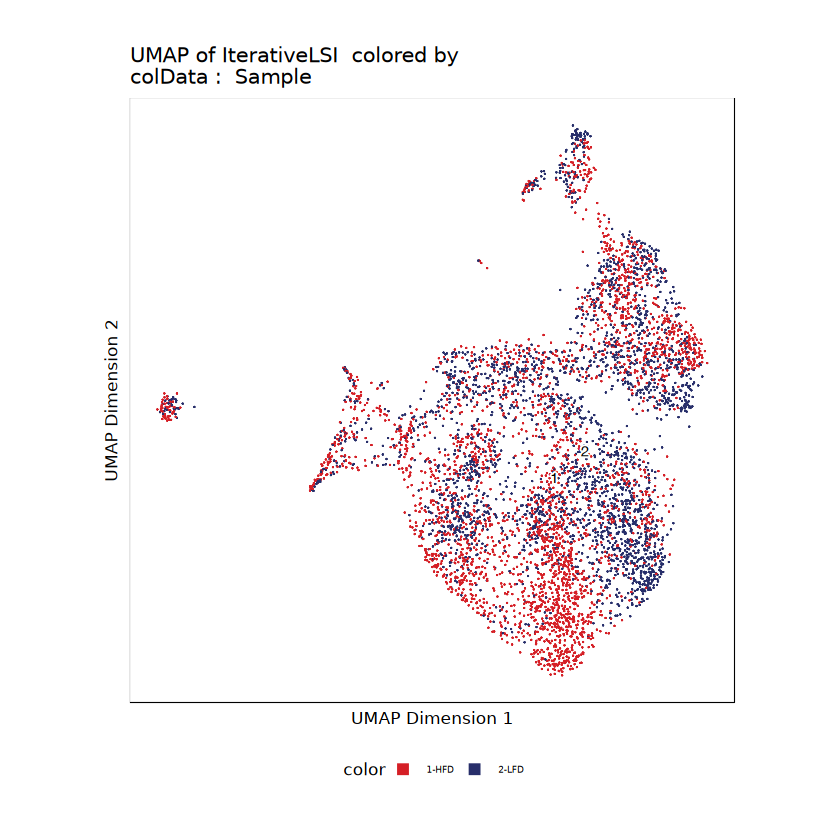

In [54]:
plotEmbedding(ArchRProj = proj, 
              colorBy = "cellColData", 
              name = "Sample",
              embedding = "UMAP",
              force = TRUE)

Calculate the number of cells per cluster and condition.

In [55]:
table(getCellColData(proj)$Clusters, getCellColData(proj)$Sample)

     
      HFD LFD
  C1  104  62
  C10 365 282
  C11 213 656
  C12 561  45
  C2   56  34
  C3   80  98
  C4  138  63
  C5  145 142
  C6  467 269
  C7  304 452
  C8  323 315
  C9  282 295

# DARs

Calculate top DARs (peak-level accessibility - actual chromatin accessibility at specific genomic regions)

In [56]:
DARs <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "PeakMatrix",
  groupBy = "Sample",  
  bias = c("TSSEnrichment", "log10(nFrags)"),
  testMethod = "wilcoxon",
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c07f2a54-Date-2025-07-29_Time-09-36-46.292082.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2025-07-29 09:36:46.386984 : Matching Known Biases, 0.001 mins elapsed.

###########
2025-07-29 09:37:02.341689 : Completed Pairwise Tests, 0.267 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-106c07f2a54-Date-2025-07-29_Time-09-36-46.292082.log



Select DARs with FDR < 0.1 and Log2FC > 1 & plot 

In [57]:
hfd_dar <- plotMarkers(seMarker = DARs, name = "HFD", cutOff = "FDR <= 0.1 & Log2FC >= 1", plotAs = "MA")
lfd_dar <- plotMarkers(seMarker = DARs, name = "LFD", cutOff = "FDR <= 0.1 & Log2FC >= 1", plotAs = "MA")


Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_point_rast()`).”


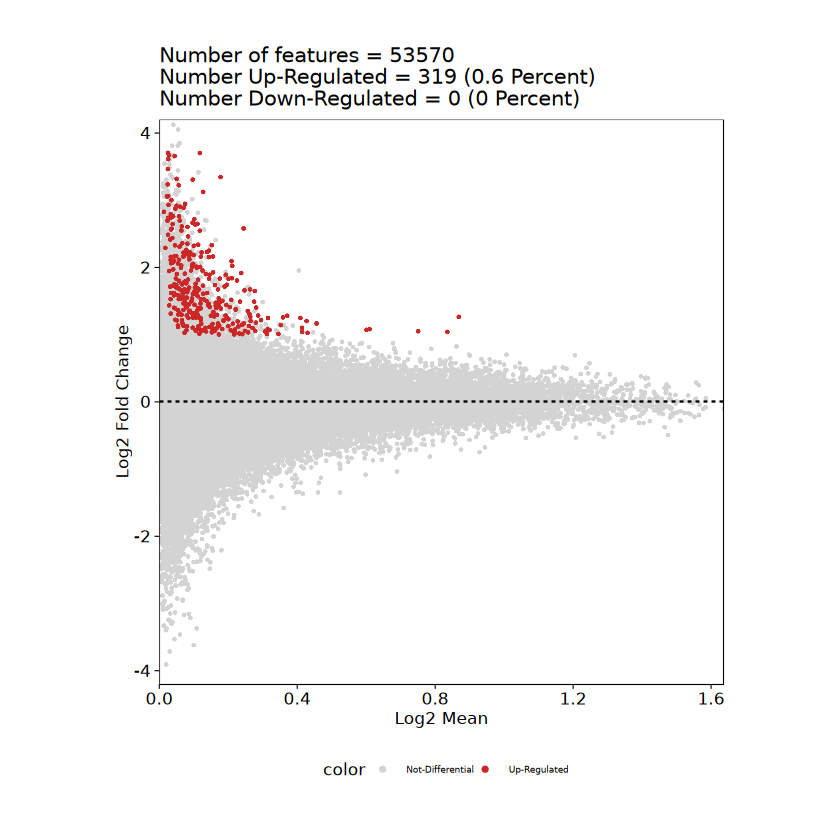

In [58]:
hfd_dar

Warning message:
“Removed 28 rows containing missing values or values outside the scale range
(`geom_point_rast()`).”


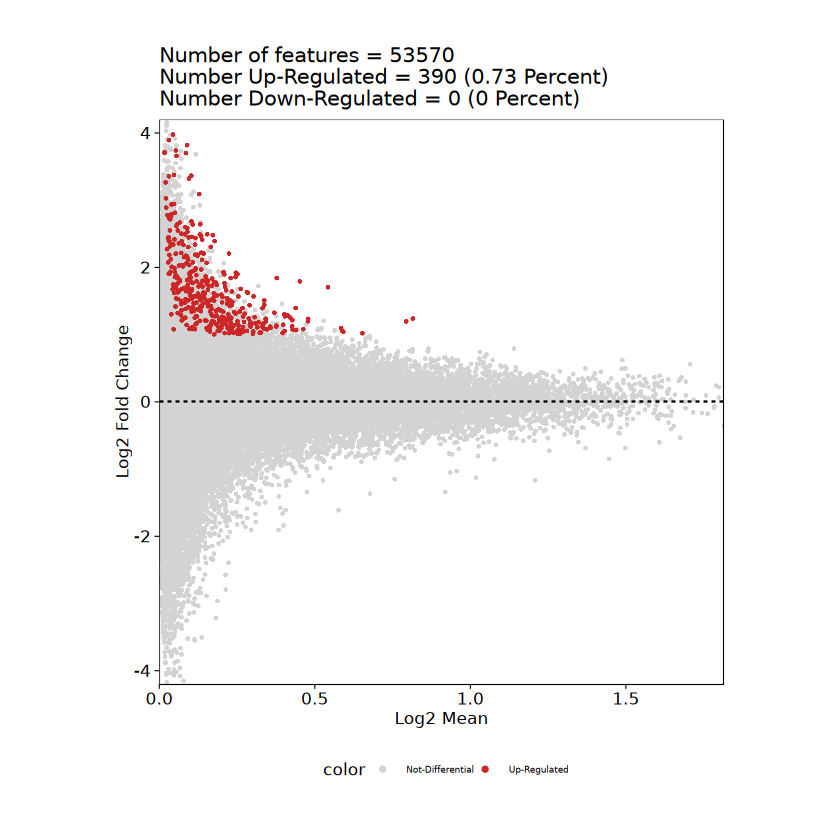

In [59]:
lfd_dar

Define function to plot the volcano plot displaying DARs in HFD vs. LFD.

In [ ]:
create_volcano_plot <- function(DARs, 
                               title = "Volcano Plot", 
                               xlab = "Log2 Fold Change", 
                               up_label = "Up", 
                               down_label = "Down",
                               log2fc_threshold = 1,
                               fdr_threshold = 0.05) {
    
    # Extract data from the DAR results
    dar_data <- assay(DARs, "Log2FC")
    dar_fdr <- assay(DARs, "FDR")
    
    if(is.list(dar_data)) {
        log2fc <- as.numeric(dar_data[[1]])
        fdr <- as.numeric(dar_fdr[[1]])
    } else {
        log2fc <- as.numeric(as.vector(dar_data))
        fdr <- as.numeric(as.vector(dar_fdr))
    }
    
    # Check for any issues
    print(paste("Log2FC range:", range(log2fc, na.rm = TRUE)))
    print(paste("FDR range:", range(fdr, na.rm = TRUE)))
    
    # Remove any NA values
    valid_indices <- !is.na(log2fc) & !is.na(fdr)
    log2fc <- log2fc[valid_indices]
    fdr <- fdr[valid_indices]
    
    # Create manual volcano plot
    plot(log2fc, -log10(fdr), 
         pch = 20, cex = 0.5, col = "grey", alpha = 0.6,
         xlab = xlab, ylab = "-log10(FDR)",
         main = title)
    
    # Add colored points for significant DARs
    significant_up <- log2fc > log2fc_threshold & fdr < fdr_threshold
    significant_down <- log2fc < -log2fc_threshold & fdr < fdr_threshold
    
    points(log2fc[significant_up], -log10(fdr[significant_up]), 
           pch = 20, cex = 0.8, col = "red")
    points(log2fc[significant_down], -log10(fdr[significant_down]), 
           pch = 20, cex = 0.8, col = "blue")
    
    # Add threshold lines
    abline(h = -log10(fdr_threshold), col = "black", lty = 2)
    abline(v = c(-log2fc_threshold, log2fc_threshold), col = "black", lty = 2)
    
    # Add legend
    legend("topright", legend = c(paste("Up in", up_label), 
                                 paste("Down in", up_label), 
                                 "Not significant"), 
           col = c("red", "blue", "grey"), pch = 20)
    
    # Return summary statistics
    return(list(
        total_points = length(log2fc),
        significant_up = sum(significant_up),
        significant_down = sum(significant_down),
        log2fc_range = range(log2fc),
        fdr_range = range(fdr)
    ))
}

[1] "Log2FC range: -3.90779600566894" "Log2FC range: 5.07208034133792" 
[1] "FDR range: 9.52953359835254e-07" "FDR range: 1"                   


Warning message in plot.window(...):
“"alpha" is not a graphical parameter”
Warning message in plot.xy(xy, type, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in box(...):
“"alpha" is not a graphical parameter”
Warning message in title(...):
“"alpha" is not a graphical parameter”


$total_points
[1] 53568

$significant_up
[1] 158

$significant_down
[1] 209

$log2fc_range
[1] -3.907796  5.072080

$fdr_range
[1] 9.529534e-07 1.000000e+00

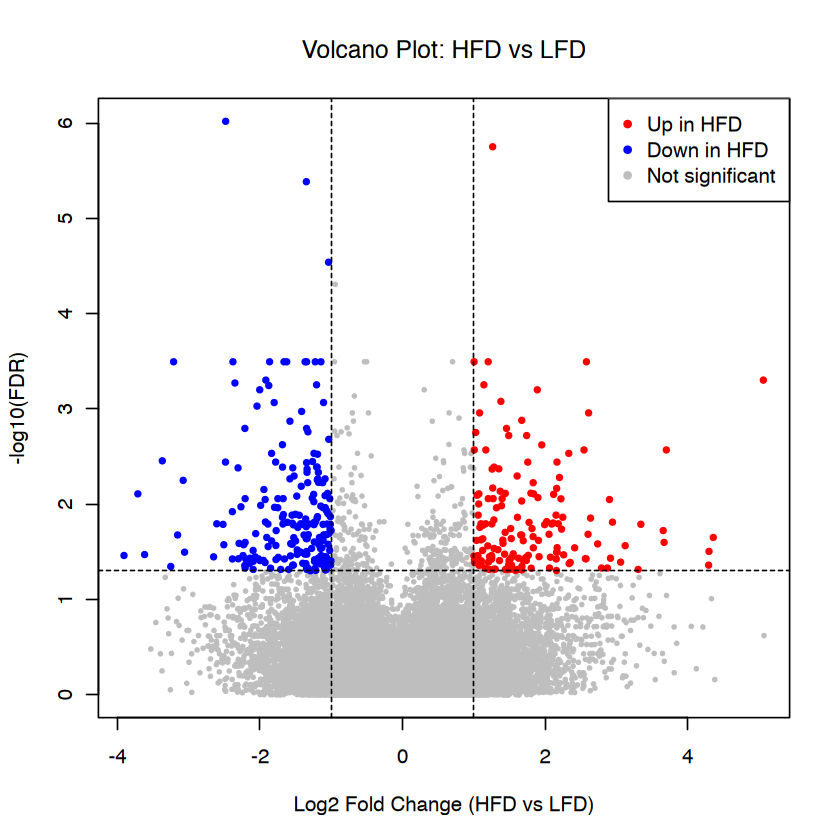

In [61]:
create_volcano_plot(DARs, 
                    title = "Volcano Plot: HFD vs LFD",
                    xlab = "Log2 Fold Change (HFD vs LFD)",
                    up_label = "HFD",
                    down_label = "LFD")

# Cluster comparison

Comparison between cluster 11 and 12 (DARs first)

In [62]:
# Get DARs between clusters 11 and 12
dar_11_12 <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "PeakMatrix",
  groupBy = "Clusters",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "C11",  # Cluster 11
  bgdGroups = "C12",   # Cluster 12
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c056e42554-Date-2025-07-29_Time-09-37-12.987737.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2025-07-29 09:37:13.159596 : Matching Known Biases, 0.001 mins elapsed.

2025-07-29 09:37:13.813648 : Computing Pairwise Tests (1 of 1), 0.012 mins elapsed.

Pairwise Test C11 : Seqnames chr1

Pairwise Test C11 : Seqnames chr10

Pairwise Test C11 : Seqnames chr11

Pairwise Test C11 : Seqnames chr12

Pairwise Test C11 : Seqnames chr13

Pairwise Test C11 : Seqnames chr14

Pairwise Test C11 : Seqnames chr15

Pairwise Test C11 : Seqnames chr16

Pairwise Test C11 : Seqnames chr17

Pairwise Test C11 : Seqnames chr18

Pairwise Test C11 : Seqnames chr19

Pairwise Test C11 : Seqnames chr2

Pairwise Test C11 : Seqnames chr3

Pairwise Test C11 : Seqnames chr4

Pairwise Test C11 : Seqnames chr5

Pairwise Test C11 : Seqnames chr6

Pairwise Test C11 : Seqnames chr7

Pairwise Test C11 : Seqnames ch

[1] "Log2FC range: -5.93826217931134" "Log2FC range: 4.11527807105404" 
[1] "FDR range: 6.90317208529236e-35" "FDR range: 1"                   


Warning message in plot.window(...):
“"alpha" is not a graphical parameter”
Warning message in plot.xy(xy, type, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in box(...):
“"alpha" is not a graphical parameter”
Warning message in title(...):
“"alpha" is not a graphical parameter”


$total_points
[1] 53553

$significant_up
[1] 1216

$significant_down
[1] 1819

$log2fc_range
[1] -5.938262  4.115278

$fdr_range
[1] 6.903172e-35 1.000000e+00

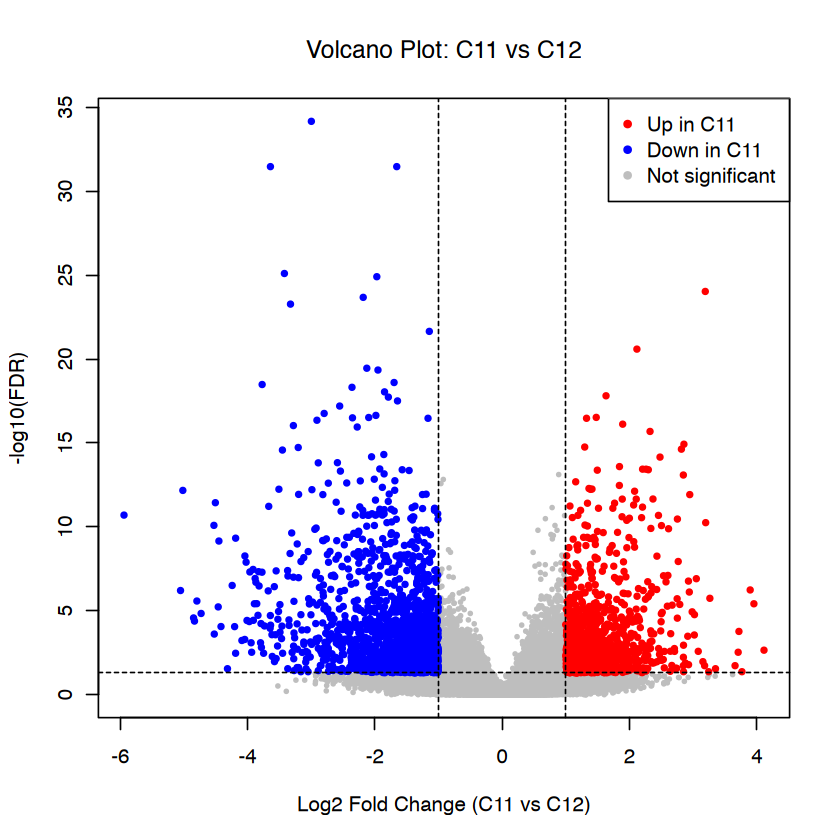

In [63]:
create_volcano_plot(dar_11_12, 
                             title = "Volcano Plot: C11 vs C12",
                             xlab = "Log2 Fold Change (C11 vs C12)",
                             up_label = "C11",
                             down_label = "C12")

Calculate gene score differences

In [64]:
# Get gene score differences between clusters 11 and 12
genes_clusters_11_12 <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Clusters",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "C11",  # Cluster 11
  bgdGroups = "C12",   # Cluster 12
)


ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c04d054100-Date-2025-07-29_Time-09-37-28.082345.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2025-07-29 09:37:28.172943 : Matching Known Biases, 0.001 mins elapsed.

2025-07-29 09:37:28.601131 : Computing Pairwise Tests (1 of 1), 0.008 mins elapsed.

Pairwise Test C11 : Seqnames chr1

Pairwise Test C11 : Seqnames chr10

Pairwise Test C11 : Seqnames chr11

Pairwise Test C11 : Seqnames chr12

Pairwise Test C11 : Seqnames chr13

Pairwise Test C11 : Seqnames chr14

Pairwise Test C11 : Seqnames chr15

Pairwise Test C11 : Seqnames chr16

Pairwise Test C11 : Seqnames chr17

Pairwise Test C11 : Seqnames chr18

Pairwise Test C11 : Seqnames chr19

Pairwise Test C11 : Seqnames chr2

Pairwise Test C11 : Seqnames chr3

Pairwise Test C11 : Seqnames chr4

Pairwise Test C11 : Seqnames chr5

Pairwise Test C11 : Seqnames chr6

Pairwise Test C11 : Seqnames chr7

Pairwise Test C11 : Seqnames chr

In [ ]:
# Extract the data from the SummarizedExperiment and save as csv
genes_df <- getMarkers(genes_clusters_11_12, cutOff = "FDR <= 1")
c11_c12 <- genes_df$C11
c11_c12_sig <- c11_c12[c11_c12$FDR < 0.05, ]
write.csv(c11_c12_sig, "significant_genes_per_cluster/c11_c12_sig.csv")

# Genome Browser Style snapshots

Plot genome browser style snapshots

Define function to plot browser track for gene of interest

In [66]:
plot_browser_track <- function(DARs, 
                              proj, 
                              gene_symbol, 
                              group_by = "Clusters",
                              fdr_cutoff = 0.05, 
                              log2fc_cutoff = 1,
                              upstream = 50000, 
                              downstream = 50000,
                              plot_title = NULL) {
    
    # Get the marker peaks
    markerPeaks <- getMarkers(DARs, 
                             cutOff = paste0("FDR <= ", fdr_cutoff, " & Log2FC >=", log2fc_cutoff), 
                             returnGR = TRUE)
    
    # Create plot title if not provided
    if(is.null(plot_title)) {
        plot_title <- paste("Browser Track:", gene_symbol)
    }
    
    # Plot browser track for gene of interest
    p <- plotBrowserTrack(
        ArchRProj = proj, 
        groupBy = group_by, 
        geneSymbol = c(gene_symbol),
        features = markerPeaks,  
        upstream = upstream,
        downstream = downstream
    )
    
    # Display the plot
    grid::grid.newpage()
    grid::grid.draw(p[[gene_symbol]])
    
    # Return the plot object and marker peaks for further use
    return(list(
        plot = p,
        marker_peaks = markerPeaks,
        gene_symbol = gene_symbol,
        n_peaks = length(markerPeaks)
    ))
}

Use function to plot specific genes of interest (comparing clusters)

ArchR logging to : ArchRLogs/ArchR-plotBrowserTrack-106c02f1c6f34-Date-2025-07-29_Time-09-37-42.693505.log
If there is an issue, please report to github with logFile!

2025-07-29 09:37:42.732426 : Validating Region, 0.001 mins elapsed.



GRanges object with 1 range and 2 metadata columns:
      seqnames          ranges strand |     gene_id      symbol
         <Rle>       <IRanges>  <Rle> | <character> <character>
  [1]     chrX 7579676-7595243      + |       20371       Foxp3
  -------
  seqinfo: 21 sequences from mm10 genome


2025-07-29 09:37:42.761453 : Adding Bulk Tracks (1 of 1), 0.001 mins elapsed.

2025-07-29 09:37:43.174981 : Adding Feature Tracks (1 of 1), 0.008 mins elapsed.

2025-07-29 09:37:43.250725 : Adding Gene Tracks (1 of 1), 0.009 mins elapsed.

2025-07-29 09:37:43.381528 : Plotting, 0.011 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-plotBrowserTrack-106c02f1c6f34-Date-2025-07-29_Time-09-37-42.693505.log



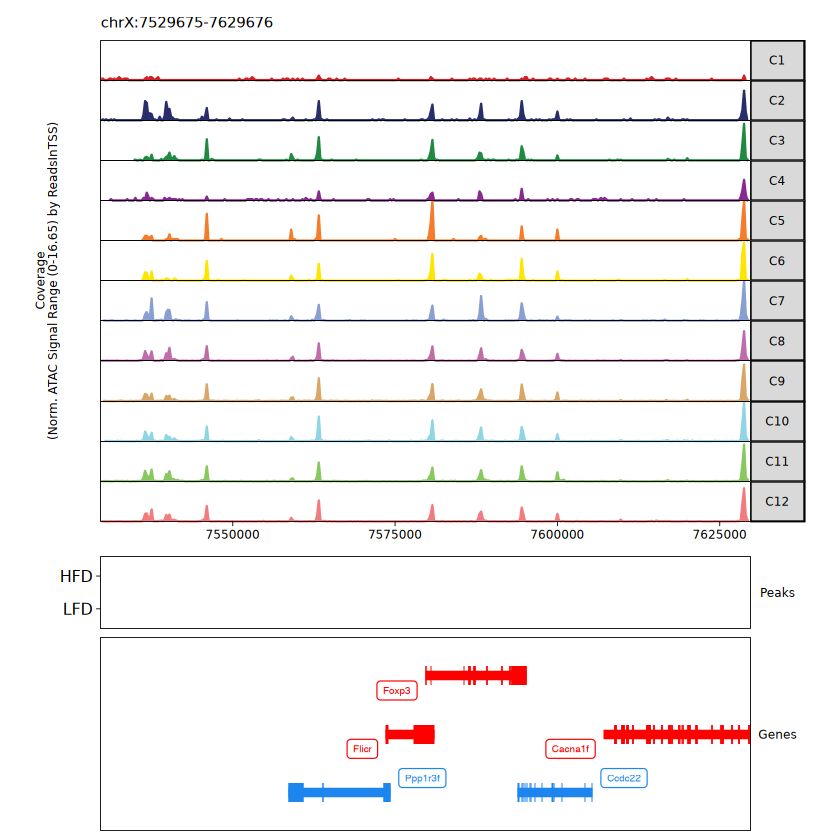

In [67]:
result <- plot_browser_track(
    DARs = DARs,
    proj = proj,
    gene_symbol = "Foxp3",
)

Plot individual gene, comparing conditions

ArchR logging to : ArchRLogs/ArchR-plotBrowserTrack-106c0395e26b3-Date-2025-07-29_Time-10-12-51.631424.log
If there is an issue, please report to github with logFile!

2025-07-29 10:12:51.666326 : Validating Region, 0.001 mins elapsed.



GRanges object with 1 range and 2 metadata columns:
      seqnames            ranges strand |     gene_id      symbol
         <Rle>         <IRanges>  <Rle> | <character> <character>
  [1]     chr1 20777146-20784270      - |      257630       Il17f
  -------
  seqinfo: 21 sequences from mm10 genome


2025-07-29 10:12:51.690327 : Adding Bulk Tracks (1 of 1), 0.001 mins elapsed.

2025-07-29 10:12:52.123573 : Adding Feature Tracks (1 of 1), 0.008 mins elapsed.

2025-07-29 10:12:52.207803 : Adding Gene Tracks (1 of 1), 0.01 mins elapsed.

2025-07-29 10:12:52.320733 : Plotting, 0.011 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-plotBrowserTrack-106c0395e26b3-Date-2025-07-29_Time-10-12-51.631424.log



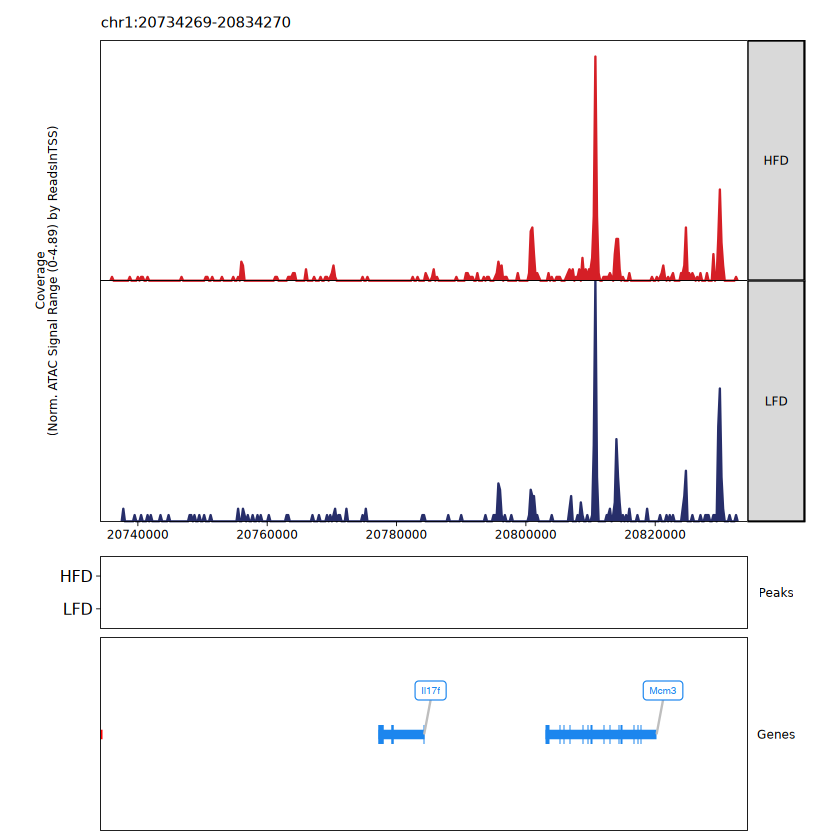

In [79]:
result <- plot_browser_track(
    DARs = DARs,
    proj = proj,
    gene_symbol = "Il17f",
    group_by = "Sample",
)

## !!! UNCOMMENT TO RUN !!!

Plots genome tracks for markerGenes, first comparing HFD vs. LFD and then comparing clusters.

In [76]:
# all_browser_plots <- list()

# # Loop through each gene, create a plot, and add it to the list
# print("Generating a browser track for each gene...")
# for (gene in markerGenes) {

#     track_data <- plot_browser_track(
#         DARs = DARs,
#         proj = proj,
#         gene_symbol = gene,
#         group_by = "Sample"
#     )
    

#     all_browser_plots <- c(all_browser_plots, track_data$plot)

# }

# # Save the entire list of collected plots to a single PDF
# plotPDF(
#     plotList = all_browser_plots,
#     name = "../../plots/Browser-Tracks_conditions.pdf",
#     ArchRProj = proj,
#     width = 8,
#     height = 6
# )


In [77]:
# all_browser_plots <- list()

# # Loop through each gene, create a plot, and add it to the list
# print("Generating a browser track for each gene...")
# for (gene in markerGenes) {

#     track_data <- plot_browser_track(
#         DARs = DARs,
#         proj = proj,
#         gene_symbol = gene
#     )
    

#     all_browser_plots <- c(all_browser_plots, track_data$plot)

# }

# # Save the entire list of collected plots to a single PDF
# plotPDF(
#     plotList = all_browser_plots,
#     name = "../../plots/Browser-Tracks_clusters.pdf",
#     ArchRProj = proj,
#     width = 8,
#     height = 6
# )


# Top DARs & annotation

Create GRanges object with all peaks (including nearest gene)

In [80]:
regions <- getPeakSet(proj)

Create GRanges object with the significant DARs

In [ ]:
DARs_gr <- getMarkers(
  DARs,
  cutOff = "FDR <= 0.05 & Log2FC >= 1",
  returnGR = TRUE
)

# Show example 
head(DARs_gr$LFD) 

GRanges object with 6 ranges and 3 metadata columns:
      seqnames              ranges strand |    Log2FC         FDR  MeanDiff
         <Rle>           <IRanges>  <Rle> | <numeric>   <numeric> <numeric>
  [1]     chr8 123275565-123276065      * |   1.19755 3.79925e-09  0.577868
  [2]    chr19     4162828-4163328      * |   1.06755 2.14670e-04  0.121742
  [3]    chr11   97894140-97894640      * |   1.23471 8.77095e-04  0.319179
  [4]    chr13   96647700-96648200      * |   2.30638 8.77095e-04  0.164082
  [5]    chr16     4696765-4697265      * |   1.50812 8.77095e-04  0.254966
  [6]     chr7   45569973-45570473      * |   1.10187 8.77095e-04  0.206909
  -------
  seqinfo: 20 sequences from an unspecified genome; no seqlengths

Convert to two dataframes - one for HFD and one for LFD

In [82]:
dar_df_hfd <- data.frame(
    Chromosome = as.character(seqnames(DARs_gr$HFD)),
    Start = start(DARs_gr$HFD),
    End = end(DARs_gr$HFD)
)

# Add the metadata columns
dar_df_hfd$Log2FC <- mcols(DARs_gr$HFD)$Log2FC
dar_df_hfd$FDR <- mcols(DARs_gr$HFD)$FDR


In [83]:
dar_df_lfd <- data.frame(
    Chromosome = as.character(seqnames(DARs_gr$LFD)),
    Start = start(DARs_gr$LFD),
    End = end(DARs_gr$LFD)
)

# Add the metadata columns
dar_df_lfd$Log2FC <- mcols(DARs_gr$LFD)$Log2FC
dar_df_lfd$FDR <- mcols(DARs_gr$LFD)$FDR

Convert regions GRanges to data frame to include nearest gene

In [84]:
regions_df <- data.frame(
    Chromosome = as.character(seqnames(regions)),
    Start = start(regions),
    End = end(regions),
    NearestGene = mcols(regions)$nearestGene,
    DistanceToGene = mcols(regions)$distToGeneStart,
    PeakType = mcols(regions)$peakType
)

Process HFD: merge by genomic coordinates (for annotation), sort & export

In [ ]:
# Merge by genomic coordinates
dar_with_genes_hfd <- merge(dar_df_hfd, regions_df, 
                       by = c("Chromosome", "Start", "End"))


# Sort by significance
top_dars_hfd <- dar_with_genes_hfd[order(dar_with_genes_hfd$FDR), ]
head(top_dars_hfd, 20)

# Save to CSV
write.csv(top_dars_hfd, "significant_dars/top_DARs_with_exact_gene_matches_hfd.csv", row.names = FALSE)


,Chromosome,Start,End,Log2FC,FDR,NearestGene,DistanceToGene,PeakType
,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<chr>
89,chr2,98497322,98497822,1.265049,1.762481e-06,Lrrc4c,2179402,Distal
19,chr11,116983464,116983964,2.580496,3.192866e-04,Mgat5b,64850,Intronic
27,chr12,76996960,76997460,1.004490,3.192866e-04,Max,34961,Distal
149,chr9,53316336,53316836,1.202107,3.192866e-04,Exph5,14915,Intronic
46,chr15,25561187,25561687,5.063092,4.973869e-04,Myo10,61112,Distal
79,chr2,103462868,103463368,1.141735,5.574049e-04,Cat,22034,Intronic
43,chr14,73286350,73286850,1.891181,6.286980e-04,Rb1,39190,Intronic
20,chr11,117689868,117690368,1.380420,8.322091e-04,Tnrc6c,35828,Intronic
17,chr10,96556762,96557262,2.611099,1.099176e-03,Btg1,59988,Distal


Process LFD: merge by genomic coordinates (for annotation), sort & export

In [ ]:
# Merge by genomic coordinates
dar_with_genes_lfd <- merge(dar_df_lfd, regions_df, 
                       by = c("Chromosome", "Start", "End"))


# Sort by significance
top_dars_lfd <- dar_with_genes_lfd[order(dar_with_genes_lfd$FDR), ]
head(top_dars_lfd, 20)

# Save to CSV
write.csv(top_dars_lfd, "significant_dars/top_DARs_with_exact_gene_matches_lfd.csv", row.names = FALSE)


,Chromosome,Start,End,Log2FC,FDR,NearestGene,DistanceToGene,PeakType
,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<int>,<chr>
141,chr8,123275565,123276065,1.197545,3.799250e-09,Vps9d1,21592,Intronic
77,chr19,4162828,4163328,1.067551,2.146704e-04,Rps6kb2,166,Intronic
37,chr11,97894140,97894640,1.234713,8.770953e-04,Fbxo47,10235,Distal
48,chr13,96647700,96648200,2.306384,8.770953e-04,Hmgcr,22985,Distal
67,chr16,4696765,4697265,1.508117,8.770953e-04,Dnaja3,12944,Intronic
134,chr7,45569973,45570473,1.101866,8.770953e-04,Bcat2,69,Promoter
96,chr3,89819349,89819849,1.342674,1.188944e-03,She,11770,Distal
29,chr11,33889418,33889918,1.792246,1.528990e-03,Kcnmb1,73344,Intronic
69,chr16,89770500,89771000,1.626850,1.528990e-03,Krtap11-1,199566,Distal


# Calculating DARs/genes for specific clusters

In [102]:
# Create a new column by pasting the cluster ID and the sample condition
proj$Cluster_Sample <- paste0(proj$Clusters, "_", proj$Sample)

print(unique(proj$Cluster_Sample))

 [1] "C1_HFD"  "C8_HFD"  "C4_HFD"  "C9_HFD"  "C5_HFD"  "C11_HFD" "C12_HFD"
 [8] "C2_HFD"  "C6_HFD"  "C7_HFD"  "C10_HFD" "C3_HFD"  "C12_LFD" "C1_LFD" 
[15] "C11_LFD" "C9_LFD"  "C8_LFD"  "C4_LFD"  "C5_LFD"  "C10_LFD" "C2_LFD" 
[22] "C3_LFD"  "C6_LFD"  "C7_LFD" 


In [103]:
# Define the clusters to analyse
clusters_to_test <- c("C5", "C6", "C8", "C9", "C12")

## DARs

In [104]:
# Initialize an empty list to store the results from each comparison
dar_results_list <- list()

# Loop through each cluster ID
for (cluster_id in clusters_to_test) {
    
    # Define the two groups to compare
    group_hfd <- paste0(cluster_id, "_HFD")
    group_lfd <- paste0(cluster_id, "_LFD")
        
    # Run the differential accessibility 
    dar_results <- getMarkerFeatures(
        ArchRProj = proj,
        useMatrix = "PeakMatrix",
        groupBy = "Cluster_Sample",
        useGroups = group_hfd, # The group of interest
        bgdGroups = group_lfd, # The group to compare against
        bias = c("TSSEnrichment", "log10(nFrags)"),
        testMethod = "wilcoxon"
    )
    
    # Store the results object (a SummarizedExperiment) in our list
    dar_results_list[[cluster_id]] <- dar_results
}

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c012123d92-Date-2025-07-29_Time-10-15-39.275466.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2025-07-29 10:15:39.407615 : Matching Known Biases, 0.002 mins elapsed.

2025-07-29 10:15:39.818307 : Computing Pairwise Tests (1 of 1), 0.008 mins elapsed.

Pairwise Test C5_HFD : Seqnames chr1

Pairwise Test C5_HFD : Seqnames chr10

Pairwise Test C5_HFD : Seqnames chr11

Pairwise Test C5_HFD : Seqnames chr12

Pairwise Test C5_HFD : Seqnames chr13

Pairwise Test C5_HFD : Seqnames chr14

Pairwise Test C5_HFD : Seqnames chr15

Pairwise Test C5_HFD : Seqnames chr16

Pairwise Test C5_HFD : Seqnames chr17

Pairwise Test C5_HFD : Seqnames chr18

Pairwise Test C5_HFD : Seqnames chr19

Pairwise Test C5_HFD : Seqnames chr2

Pairwise Test C5_HFD : Seqnames chr3

Pairwise Test C5_HFD : Seqnames chr4

Pairwise Test C5_HFD : Seqnames chr5

Pairwise Test C5_HFD : Seqnames chr6

Pairwise Test C5_H

Save specific results

In [105]:
cluster = "C12"

In [ ]:
# Get the results for specifcied cluster
results <- dar_results_list[[cluster]]

df <- as.data.frame(rowData(results))
df$Log2FC <- assay(results, "Log2FC")[,1]
df$FDR <- assay(results, "FDR")[,1]

# Filter for significant results (e.g., FDR <= 0.05 and |Log2FC| >= 1)
significant_df <- df[which(df$FDR <= 0.05 & abs(df$Log2FC) >= 1), ]

# Sort to see the top regions more accessible in HFD
significant_df_HFD <- significant_df[order(significant_df$Log2FC, decreasing = TRUE), ]

# Sort to see the top regions more accessible in LFD
significant_df_LFD <- significant_df[order(significant_df$Log2FC, decreasing = FALSE), ]


print("Top 5 DARs more accessible in HFD:")
print(cluster)
print(head(significant_df_HFD))

print("Top 5 DARs more accessible in LFD:")
print(cluster)
print(head(significant_df_LFD))

# Save to a CSV file
filename <- sprintf("significant_dars/DARs_HFD_vs_LFD_in_%s.csv", cluster)
write.csv(significant_df, file = filename)

[1] "Top 5 DARs more accessible in HFD:"
[1] "C12"
      seqnames  idx     start       end   Log2FC        FDR
36969     chr4 2924 145037397 145037897 2.212777 0.03483837
34907     chr4  862  59331545  59332045 1.826354 0.03483837
[1] "Top 5 DARs more accessible in LFD:"
[1] "C12"
      seqnames  idx     start       end   Log2FC        FDR
34907     chr4  862  59331545  59332045 1.826354 0.03483837
36969     chr4 2924 145037397 145037897 2.212777 0.03483837


## Gene Score

Same as above but with useMatrix = "GeneScoreMatrix"

In [107]:
gene_results_list <- list()

for (cluster_id in clusters_to_test) {
    
    group_hfd <- paste0(cluster_id, "_HFD")
    group_lfd <- paste0(cluster_id, "_LFD")
    
    
    # Same as above but GeneScoreMatrix
    gene_results <- getMarkerFeatures(
        ArchRProj = proj,
        useMatrix = "GeneScoreMatrix",
        groupBy = "Cluster_Sample",
        useGroups = group_hfd, 
        bgdGroups = group_lfd, 
        bias = c("TSSEnrichment", "log10(nFrags)"),
        testMethod = "wilcoxon"
    )
    
    gene_results_list[[cluster_id]] <- gene_results
}

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c052dd6aef-Date-2025-07-29_Time-10-16-56.393252.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2025-07-29 10:16:56.515255 : Matching Known Biases, 0.001 mins elapsed.

2025-07-29 10:16:56.94726 : Computing Pairwise Tests (1 of 1), 0.008 mins elapsed.

Pairwise Test C5_HFD : Seqnames chr1

Pairwise Test C5_HFD : Seqnames chr10

Pairwise Test C5_HFD : Seqnames chr11

Pairwise Test C5_HFD : Seqnames chr12

Pairwise Test C5_HFD : Seqnames chr13

Pairwise Test C5_HFD : Seqnames chr14

Pairwise Test C5_HFD : Seqnames chr15

Pairwise Test C5_HFD : Seqnames chr16

Pairwise Test C5_HFD : Seqnames chr17

Pairwise Test C5_HFD : Seqnames chr18

Pairwise Test C5_HFD : Seqnames chr19

Pairwise Test C5_HFD : Seqnames chr2

Pairwise Test C5_HFD : Seqnames chr3

Pairwise Test C5_HFD : Seqnames chr4

Pairwise Test C5_HFD : Seqnames chr5

Pairwise Test C5_HFD : Seqnames chr6

Pairwise Test C5_HFD

In [108]:
cluster = "C12"

In [ ]:
# Get the results for specifcied cluster
results <- gene_results_list[[cluster]]

df <- as.data.frame(rowData(results))
df$Log2FC <- assay(results, "Log2FC")[,1]
df$FDR <- assay(results, "FDR")[,1]

# Filter for significant results (e.g., FDR <= 0.05 and |Log2FC| >= 1)
significant_df <- df[which(df$FDR <= 0.05 & abs(df$Log2FC) >= 1), ]

# Sort to see the top regions more accessible in HFD
significant_df_HFD <- significant_df[order(significant_df$Log2FC, decreasing = TRUE), ]

# Sort to see the top regions more accessible in LFD
significant_df_LFD <- significant_df[order(significant_df$Log2FC, decreasing = FALSE), ]


print("HFD:")
print(cluster)
print(head(significant_df_HFD))

print("LFD:")
print(cluster)
print(head(significant_df_LFD))

# Save to a CSV file
filename <- sprintf("significant_genes_per_cluster/Genes_HFD_vs_LFD_in_%s.csv", cluster)
write.csv(significant_df, file = filename)

[1] "HFD:"
[1] "C12"
[1] seqnames start    end      strand   name     idx      Log2FC   FDR     
<0 rows> (or 0-length row.names)
[1] "LFD:"
[1] "C12"
[1] seqnames start    end      strand   name     idx      Log2FC   FDR     
<0 rows> (or 0-length row.names)


# Visualizations for figures

In [110]:
umap_df <- getEmbedding(ArchRProj = proj, embedding = "UMAP", returnDF = TRUE)


In [111]:
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

head(umap_df)

,UMAP1,UMAP2
,<dbl>,<dbl>
HFD#TTCTGTAGTGCTGAAG-1,-7.081218,0.3855501
HFD#GTTATGGGTTCCATCC-1,-7.504529,0.4610944
HFD#ACTAACGGTGAGCTAG-1,5.388268,3.0420845
HFD#TTACGTTGTCATCGTA-1,3.494819,2.7703350
HFD#TGAGCCGAGCCTGGTC-1,-6.799176,1.5107713
HFD#TTGCGAACAAAGGAAG-1,2.709253,3.8681028


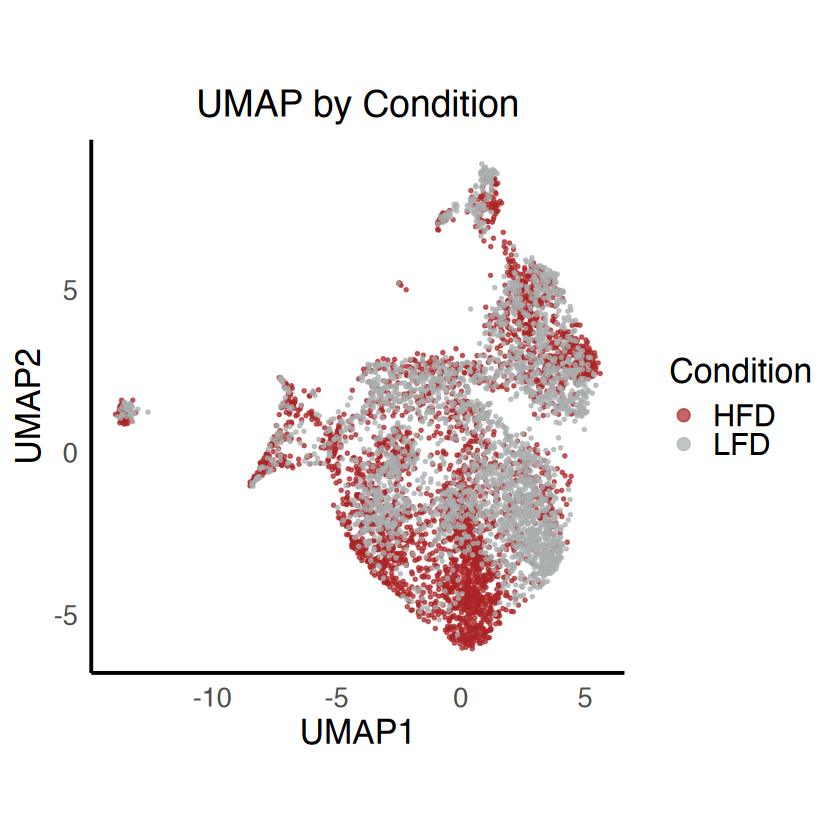

In [ ]:
# Extract sample names from the rownames (everything before the #)
umap_df$Sample <- sapply(strsplit(rownames(umap_df), "#"), function(x) x[1])

p1 <- ggplot(umap_df, aes(x = `UMAP1`, y = `UMAP2`, color = Sample)) +
  geom_point(size = 0.5, alpha = 0.7) +
  scale_color_manual(values = c("HFD" = "#ab2426", "LFD" = "#a9aeae")) +
  labs(
    title = "UMAP by Condition",
    color = "Condition",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    legend.title = element_text(size = 20),
    legend.text = element_text(size = 18),
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  ) +
  guides(color = guide_legend(override.aes = list(size = 3))) 

print(p1)

ggsave("plots/umap_by_condition.svg", plot = p1, width = 10, height = 8, dpi = 300)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


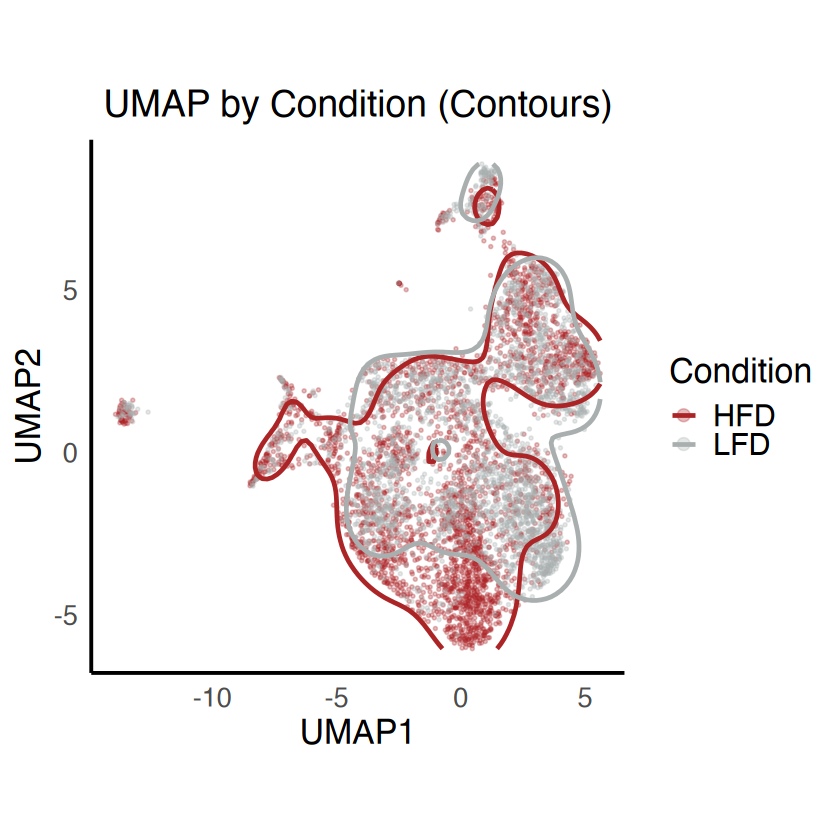

In [113]:
ggplot(umap_df, aes(x = `UMAP1`, y = `UMAP2`, color = Sample)) +
  geom_point(size = 0.5, alpha = 0.3) +
  stat_density_2d(aes(color = Sample), geom = "contour", 
                  contour_var = "ndensity", breaks = 0.2, size = 1) +
  scale_color_manual(values = c("HFD" = "#ab2426", "LFD" = "#a9aeae")) +
  labs(
    title = "UMAP by Condition (Contours)",
    color = "Condition",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    legend.title = element_text(size = 20),
    legend.text = element_text(size = 18),
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  ) +
  guides(color = guide_legend(override.aes = list(size = 3))) +
  coord_cartesian(clip = "off")

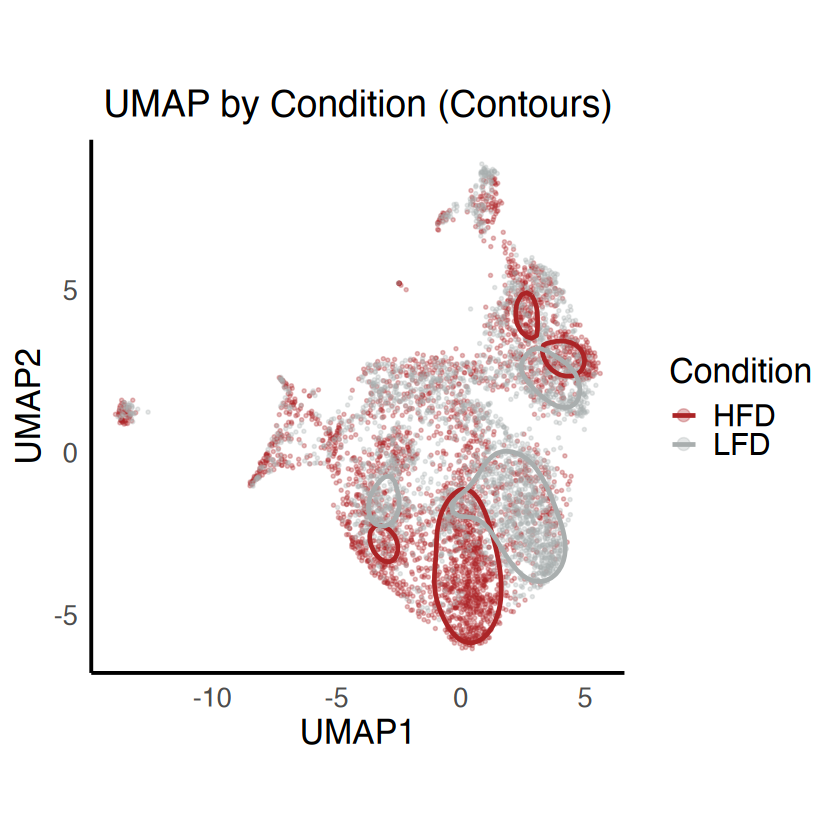

In [114]:
# Method 2: Use density contours for cluster 12 only
cluster12_data <- umap_df[umap_df$Cluster == "C12", ]

ggplot(umap_df, aes(x = `UMAP1`, y = `UMAP2`, color = Sample)) +
  geom_point(size = 0.5, alpha = 0.3) +
  stat_density_2d(aes(color = Sample), geom = "contour", 
                  contour_var = "ndensity", breaks = 0.5, size = 1) +
  # Add density contour for cluster 12 only
  stat_density_2d(data = cluster12_data, aes(x = `UMAP1`, y = `UMAP2`), 
                  geom = "contour", color = "black", linetype = "dashed", 
                  size = 1, breaks = 0.05) +  # Adjust breaks for tighter boundary
  scale_color_manual(values = c("HFD" = "#ab2426", "LFD" = "#a9aeae")) +
  labs(
    title = "UMAP by Condition (Contours)",
    color = "Condition",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    legend.title = element_text(size = 20),
    legend.text = element_text(size = 18),
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  ) +
  guides(color = guide_legend(override.aes = list(size = 3))) +
  coord_cartesian(clip = "off")

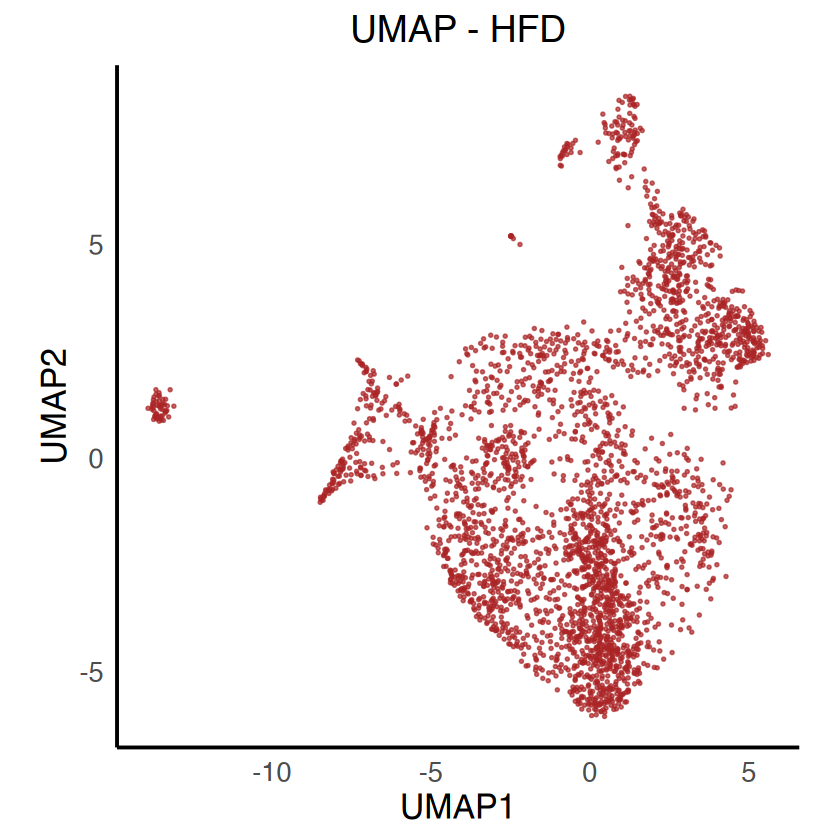

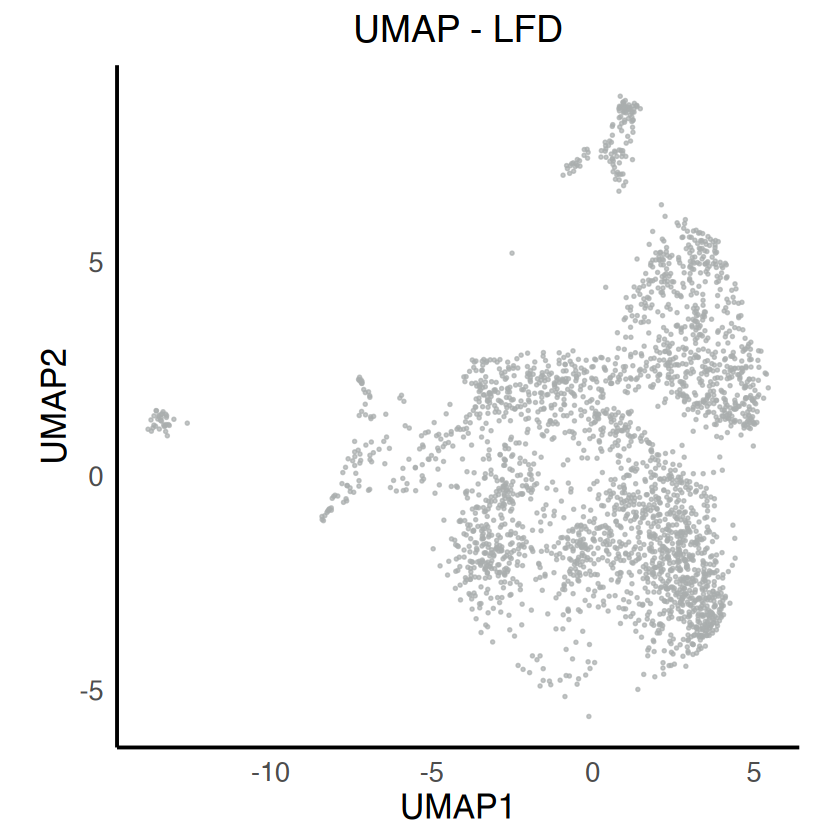

In [ ]:
# Extract sample names from the rownames (everything before the #)
umap_df$Sample <- sapply(strsplit(rownames(umap_df), "#"), function(x) x[1])

# Filter data for HFD only
hfd_df <- umap_df[umap_df$Sample == "HFD", ]

# HFD plot
p_hfd <- ggplot(hfd_df, aes(x = `UMAP1`, y = `UMAP2`)) +
  geom_point(size = 0.5, alpha = 0.7, color = "#ab2426") +
  labs(
    title = "UMAP - HFD",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  )

# Filter data for LFD only
lfd_df <- umap_df[umap_df$Sample == "LFD", ]

# LFD plot
p_lfd <- ggplot(lfd_df, aes(x = `UMAP1`, y = `UMAP2`)) +
  geom_point(size = 0.5, alpha = 0.7, color = "#a9aeae") +
  labs(
    title = "UMAP - LFD",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  )

# Display both plots
print(p_hfd)
print(p_lfd)

# Save both plots
ggsave("plots/umap_HFD.svg", plot = p_hfd, width = 10, height = 8, dpi = 300)
ggsave("plots/umap_LFD.svg", plot = p_lfd, width = 10, height = 8, dpi = 300)

Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c07f8d1f3-Date-2025-07-29_Time-10-28-05.997828.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 10:28:06.170874 : 



Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-106c07f8d1f3-Date-2025-07-29_Time-10-28-05.997828.log

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-106c0609fac9b-Date-2025-07-29_Time-10-28-07.879359.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2025-07-29 10:28:08.073934 : 



Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

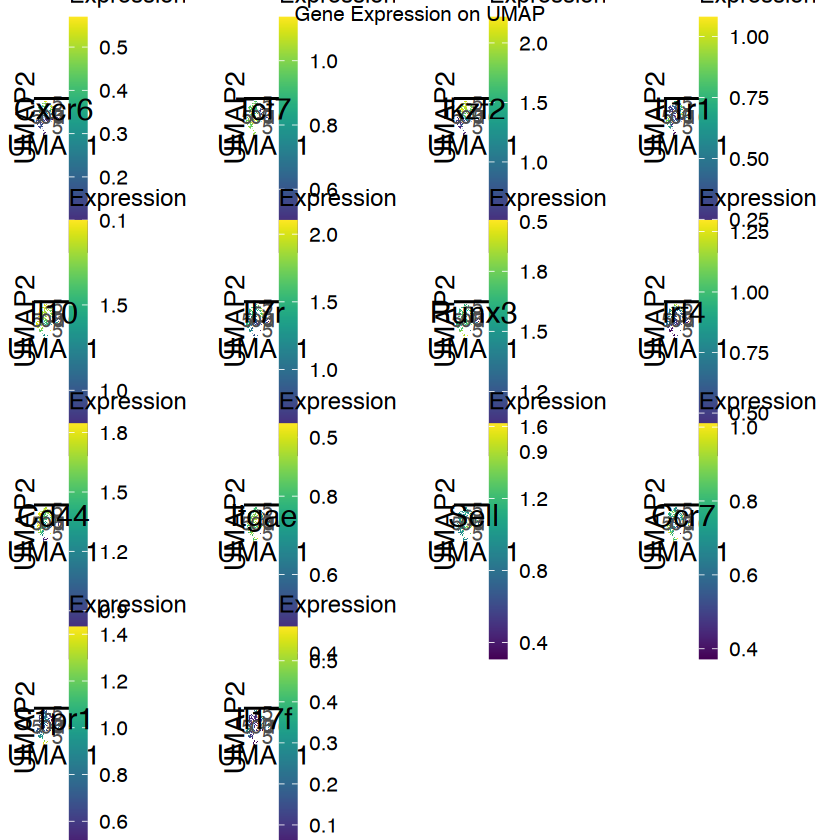

In [ ]:
genes_to_plot <- c("Cxcr6", "Tcf7", "Ikzf2", "Il1r1", "Il10", "Il7r", "Runx3", "Irf4", 
                   "Cd44", "Itgae", "Sell", "Ccr7", "S1pr1", "Il17f")

# Create gene expression plots
gene_plots <- list()

for(gene in genes_to_plot) {
  tryCatch({
    p <- plotEmbedding(
      ArchRProj = proj,
      colorBy = "GeneScoreMatrix",
      name = gene,
      embedding = "UMAP",
      size = 0.5,
      plotAs = "points"
    ) +
      scale_color_viridis(name = "Expression") +
      labs(
        title = gene,
        x = "UMAP1",
        y = "UMAP2"
      ) +
      theme_minimal(base_size = 14) +
      theme(
        panel.grid.minor = element_blank(),
        panel.grid.major = element_blank(),
        axis.line = element_line(color = "black"),
        aspect.ratio = 1,
        axis.title = element_text(size = 16),
        axis.text = element_text(size = 12),
        plot.title = element_text(size = 18, hjust = 0.5, face = "bold"),
        legend.title = element_text(size = 14),
        legend.text = element_text(size = 12),
        plot.margin = unit(c(0.3, 0.3, 0.3, 0.3), "cm"),  
        legend.position = "right",
        legend.key.height = unit(1, "cm"),
        legend.key.width = unit(0.4, "cm")
      )
    
    gene_plots[[gene]] <- p
  }, error = function(e) {
    message(paste("Could not plot gene:", gene, "-", e$message))
  })
}

# Arrange plots in a grid
if(length(gene_plots) > 0) {
  grid_plot <- do.call(grid.arrange, c(gene_plots, 
                                       ncol = 4,
                                       top = "Gene Expression on UMAP"))
  
  # Save 
  ggsave("plots/gene_expression_umap.svg", grid_plot, width = 28, height = 22, dpi = 300)
}

# Cell-type specific analysis 
(With merged clusters)

## Rename & replot clusters

In [123]:
proj$Clusters_renamed <- proj$Clusters
proj$Clusters_renamed[proj$Clusters_renamed %in% c("C1", "C4")] <- "Circulating T cells"
proj$Clusters_renamed[proj$Clusters_renamed == "C3"] <- "Circulating/Transitional"
proj$Clusters_renamed[proj$Clusters_renamed %in% c("C2", "C5", "C6", "C7", "C8", "C9", "C10", "C11", "C12", "C13")] <- "Tissue-resident T cells"

Check that renaming worked

In [124]:
table(proj$Clusters_renamed)



     Circulating T cells Circulating/Transitional  Tissue-resident T cells 
                     367                      178                     5206 

In [ ]:
umap_df <- getEmbedding(ArchRProj = proj, embedding = "UMAP")

colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

umap_df$Clusters_renamed <- proj$Clusters_renamed

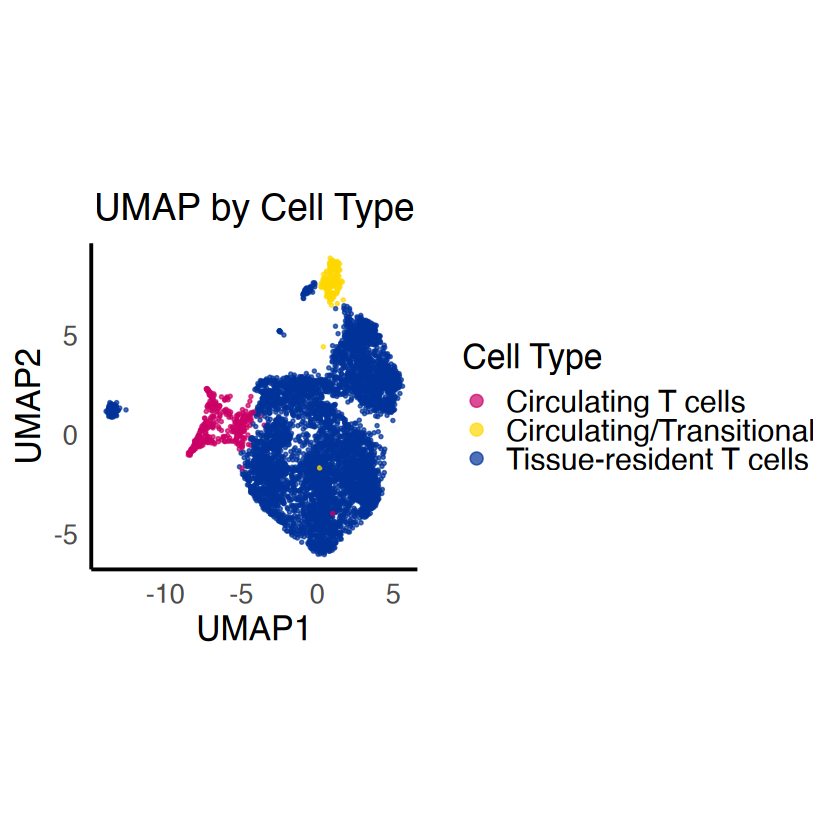

In [139]:
p1 <- ggplot(umap_df, aes(x = `UMAP1`, y = `UMAP2`, color = Clusters_renamed)) +
  geom_point(size = 0.5, alpha = 0.7) +
  scale_color_manual(values = c(
    "Tissue-resident T cells" = "#003399",
    "Circulating T cells" = "#cc0066", 
    "Circulating/Transitional" = "gold"
  )) +
  labs(
    title = "UMAP by Cell Type",
    color = "Cell Type",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    legend.title = element_text(size = 20),
    legend.text = element_text(size = 18),
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  ) +
  guides(color = guide_legend(override.aes = list(size = 3))) 

print(p1)

ggsave("plots/UMAP_cell_types.svg", p1, width = 10, height = 8, dpi = 300)

In [ ]:
# Get gene score differences between the three clusters
genes_celltypes <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Clusters_renamed",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-106c01b3372b-Date-2025-07-30_Time-12-57-50.619922.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2025-07-30 12:57:50.794784 : Matching Known Biases, 0.002 mins elapsed.

###########
2025-07-30 12:58:14.996328 : Completed Pairwise Tests, 0.405 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-106c01b3372b-Date-2025-07-30_Time-12-57-50.619922.log



In [147]:
genes_df_celltype$`Circulating T cells`

DataFrame with 23925 rows and 9 columns
      seqnames     start       end    strand          name       idx    Log2FC
         <Rle> <integer> <integer> <integer>   <character> <integer> <numeric>
1966     chr10  80539124  80519585         2        Atp8b3       608  -2.17650
6538     chr14  54464147  54470292         1         Lrp10       424  -1.99071
3587     chr11  86484657  86499007         1         Rnft1      1082  -3.15395
3607     chr11  87617164  87659542         1          Hsf5      1102  -2.05635
9363     chr17  36286421  36284227         2      H2-M10.2       691  -2.41805
...        ...       ...       ...       ...           ...       ...       ...
23605     chrX  52742192  52742113         2        Mir20b       315  1.273693
23606     chrX  52742413  52742331         2        Mir18b       316  1.274975
23715     chrX  70385913  70389416         1 1110012L19Rik       425 -0.468438
24188     chrX 147010601 147010686         1       Mir1264       898 -1.856574
24189     ch

In [ ]:
genes_df_celltype <- getMarkers(genes_celltypes, cutOff = "FDR <= 1")

# Get all FDR columns and select the ones that are < 0.05
fdr_cols <- grep("FDR", names(genes_df_celltype), value = TRUE)
fdr_condition <- Reduce(`|`, lapply(fdr_cols, function(col) {
    genes_df_celltype[[col]] < 0.05
}))

genes_celltypes_sig <- genes_df_celltype[fdr_condition, ]

# Save as csv
write.csv(genes_df_celltype, "genes_celltypes_sig.csv")

List of length 3
names(3): Circulating T cells Circulating/Transitional Tissue-resident T cells
